<a href="https://colab.research.google.com/github/davidlealo/sic_ia_2026/blob/main/ejercicios_profesor/sic2026_ia_clase13_temas_embeddings_lstm_PROFESOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIC 2026 · Inteligencia Artificial
## Clase 13: Representación de texto, temas, embeddings y LSTM

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

Terminamos el Capítulo 7, desde la lámina 114, con las mismas reseñas de productos Samsung de las clases anteriores.

| Hora | Parte | Láminas | Qué vamos a hacer |
|---|---|---|---|
| 08:00 a 08:15 | 0. Retomar | | Cargar las reseñas y las funciones de las clases anteriores |
| 08:15 a 09:00 | 1. TF-IDF y similitud coseno | 114 a 125 | TF-IDF paso a paso y un buscador de reseñas parecidas |
| 09:00 a 09:30 | 2. Clasificación | 127 a 133 | Naive Bayes contra regresión logística |
| 09:30 a 09:40 | Pausa | | |
| 09:40 a 10:40 | 3. Modelado de temas | 135 a 154 | LSA y LDA paso a paso, y con las reseñas |
| 10:40 a 11:10 | 4. Embeddings y skip-gram | 156 a 167 | Vectores de palabras |
| 11:10 a 11:55 | 5. LSTM | 168 a 175 | Clasificar reseñas leyendo en orden |
| 11:55 a 12:00 | Cierre | | |

Cada paso tiene **qué vamos a hacer**, **el código** y **qué deberías ver**. Los ejercicios tienen verificación y las soluciones están al final.

In [ ]:
texto = "It was the best of times, it was the worst of times, it was the age of wisdom, it was the age of foolishness"

In [ ]:
texto_minuscula = texto.lower()
print(texto_minuscula)

it was the best of times, it was the worst of times, it was the age of wisdom, it was the age of foolishness


In [ ]:
# contar la frecuencia de palabras de texto_minuscula
from collections import Counter
frecuencias = Counter(texto_minuscula.split())
print(frecuencias)

Counter({'it': 4, 'was': 4, 'the': 4, 'of': 4, 'times,': 2, 'age': 2, 'best': 1, 'worst': 1, 'wisdom,': 1, 'foolishness': 1})


In [ ]:
stopwords_propias = ["it", "the", "of"]

In [ ]:
# Eliminar de texto_minuscula las stopwordds_propias
texto_sin_stopwords = " ".join([palabra for palabra in texto_minuscula.split() if palabra not in stopwords_propias])
print(texto_sin_stopwords)

was best times, was worst times, was age wisdom, was age foolishness


In [ ]:
# contar la frecuencia de palabras de texto_sin_stopwords
from collections import Counter
frecuencias = Counter(texto_sin_stopwords.split())
print(frecuencias)

Counter({'was': 4, 'times,': 2, 'age': 2, 'best': 1, 'worst': 1, 'wisdom,': 1, 'foolishness': 1})


In [ ]:
# Crear a mano sin librerias un DTM y TDM de texto_sin_stopwords


In [ ]:
# Separamos el texto en oraciones (documentos) usando las comas como separador de documentos
documentos = [doc.strip() for doc in texto_sin_stopwords.split(',')]

# Obtenemos el vocabulario único (limpiando posibles puntuaciones menores de forma simple)
vocabulario = sorted(list(set(palabra.replace(',', '').replace('.', '') for doc in documentos for palabra in doc.split())))

# 1. Crear el DTM (Filas: Documentos, Columnas: Palabras)
dtm = []
for doc in documentos:
    palabras_doc = doc.split()
    fila = [palabras_doc.count(palabra) for palabra in vocabulario]
    dtm.append(fila)

# 2. Crear el TDM (Transpuesta del DTM: Filas: Palabras, Columnas: Documentos)
tdm = list(map(list, zip(*dtm)))

# Mostramos los resultados
print("Vocabulario:", vocabulario)
print("\nDocument-Term Matrix (DTM):")
for i, fila in enumerate(dtm):
    print(f"Doc {i+1}: {fila}")

print("\nTerm-Document Matrix (TDM):")
for i, palabra in enumerate(vocabulario):
    print(f"{palabra:<12}: {tdm[i]}")

Vocabulario: ['age', 'best', 'foolishness', 'times', 'was', 'wisdom', 'worst']

Document-Term Matrix (DTM):
Doc 1: [0, 1, 0, 1, 1, 0, 0]
Doc 2: [0, 0, 0, 1, 1, 0, 1]
Doc 3: [1, 0, 0, 0, 1, 1, 0]
Doc 4: [1, 0, 1, 0, 1, 0, 0]

Term-Document Matrix (TDM):
age         : [0, 0, 1, 1]
best        : [1, 0, 0, 0]
foolishness : [0, 0, 0, 1]
times       : [1, 1, 0, 0]
was         : [1, 1, 1, 1]
wisdom      : [0, 0, 1, 0]
worst       : [0, 1, 0, 0]


In [ ]:
# Documentos proporcionados por el usuario
documentos_nuevos = [
    'the economic slowdown is becoming more severe',
    'the movie was simply awesome',
    'i like cooking my own food',
    'samsung is announcing a new technology',
    'machine learning is an example of awesome technology',
    'all of us were excited at the movie',
    'we have to do more to reverse the economic slowdown'
]

# Obtener el vocabulario único limpiando puntuación básica y pasando a minúsculas
vocab_nuevo = sorted(list(set(
    palabra.strip(".,!?()")
    for doc in documentos_nuevos
    for palabra in doc.lower().split()
)))

# 1. Crear el DTM (Filas: Documentos, Columnas: Palabras)
dtm_nuevo = []
for doc in documentos_nuevos:
    palabras_doc = [p.strip(".,!?()") for p in doc.lower().split()]
    fila = [palabras_doc.count(palabra) for palabra in vocab_nuevo]
    dtm_nuevo.append(fila)

# 2. Crear el TDM (Transpuesta del DTM)
tdm_nuevo = list(map(list, zip(*dtm_nuevo)))

# Mostrar los resultados estructurados
print("Vocabulario Nuevo:", vocab_nuevo)
print(f"\nTamaño del vocabulario: {len(vocab_nuevo)} palabras")

print("\nDocument-Term Matrix (DTM) - Primeros 3 documentos:")
for i, fila in enumerate(dtm_nuevo[:3]):
    print(f"Doc {i+1}: {fila}")

print("\nTerm-Document Matrix (TDM) - Primeras 10 palabras:")
for i, palabra in enumerate(vocab_nuevo[:10]):
    print(f"{palabra:<12}: {tdm_nuevo[i]}")

Vocabulario Nuevo: ['a', 'all', 'an', 'announcing', 'at', 'awesome', 'becoming', 'cooking', 'do', 'economic', 'example', 'excited', 'food', 'have', 'i', 'is', 'learning', 'like', 'machine', 'more', 'movie', 'my', 'new', 'of', 'own', 'reverse', 'samsung', 'severe', 'simply', 'slowdown', 'technology', 'the', 'to', 'us', 'was', 'we', 'were']

Tamaño del vocabulario: 37 palabras

Document-Term Matrix (DTM) - Primeros 3 documentos:
Doc 1: [0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0]
Doc 2: [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0]
Doc 3: [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Term-Document Matrix (TDM) - Primeras 10 palabras:
a           : [0, 0, 0, 1, 0, 0, 0]
all         : [0, 0, 0, 0, 0, 1, 0]
an          : [0, 0, 0, 0, 1, 0, 0]
announcing  : [0, 0, 0, 1, 0, 0, 0]
at          : [0

In [ ]:
from nltk.corpus import stopwords

# Obtener lista de stopwords en inglés
stop_words = set(stopwords.words('english'))

# Filtrar tokens quitando puntuación y stopwords
documentos_filtrados = []
for doc in documentos_nuevos:
    palabras = [p.strip(".,!?()") for p in doc.lower().split()]
    palabras_sin_stop = [p for p in palabras if p and p not in stop_words]
    documentos_filtrados.append(palabras_sin_stop)

# Obtener el vocabulario único sin stopwords
vocab_filtrado = sorted(list(set(palabra for doc in documentos_filtrados for palabra in doc)))

# 1. Crear el DTM (Filas: Documentos, Columnas: Palabras)
dtm_filtrado = []
for doc in documentos_filtrados:
    fila = [doc.count(palabra) for palabra in vocab_filtrado]
    dtm_filtrado.append(fila)

# 2. Crear el TDM (Transpuesta del DTM)
tdm_filtrado = list(map(list, zip(*dtm_filtrado)))

# Mostrar resultados
print("Vocabulario Filtrado (sin stopwords):", vocab_filtrado)
print(f"\nTamaño del nuevo vocabulario: {len(vocab_filtrado)} palabras (antes eran 37)")

print("\nDocument-Term Matrix (DTM) - Primeros 3 documentos:")
for i, fila in enumerate(dtm_filtrado[:3]):
    print(f"Doc {i+1}: {fila}")

print("\nTerm-Document Matrix (TDM) - Primeras 10 palabras:")
for i, palabra in enumerate(vocab_filtrado[:10]):
    print(f"{palabra:<12}: {tdm_filtrado[i]}")

Vocabulario Filtrado (sin stopwords): ['announcing', 'awesome', 'becoming', 'cooking', 'economic', 'example', 'excited', 'food', 'learning', 'like', 'machine', 'movie', 'new', 'reverse', 'samsung', 'severe', 'simply', 'slowdown', 'technology', 'us']

Tamaño del nuevo vocabulario: 20 palabras (antes eran 37)

Document-Term Matrix (DTM) - Primeros 3 documentos:
Doc 1: [0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0]
Doc 2: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]
Doc 3: [0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Term-Document Matrix (TDM) - Primeras 10 palabras:
announcing  : [0, 0, 0, 1, 0, 0, 0]
awesome     : [0, 1, 0, 0, 1, 0, 0]
becoming    : [1, 0, 0, 0, 0, 0, 0]
cooking     : [0, 0, 1, 0, 0, 0, 0]
economic    : [1, 0, 0, 0, 0, 0, 1]
example     : [0, 0, 0, 0, 1, 0, 0]
excited     : [0, 0, 0, 0, 0, 1, 0]
food        : [0, 0, 1, 0, 0, 0, 0]
learning    : [0, 0, 0, 0, 1, 0, 0]
like        : [0, 0, 1, 0, 0, 0, 0]


In [ ]:
import numpy as np
import pandas as pd

# Número total de documentos (n = 7)
n = len(documentos_nuevos)

# Calcular DF (Document Frequency) para cada palabra del vocabulario filtrado
df_filtrado = {}
for palabra in vocab_filtrado:
    # Contamos en cuántos documentos aparece la palabra
    df_filtrado[palabra] = sum(1 for doc in documentos_filtrados if palabra in doc)

# Calcular IDF usando la fórmula estándar de scikit-learn:
# IDF(t) = log((1 + n) / (1 + DF(t))) + 1
idf_filtrado = {}
for palabra, df in df_filtrado.items():
    idf_filtrado[palabra] = np.log((1 + n) / (1 + df)) + 1

# Convertir a un DataFrame para mostrarlo ordenado y estético
df_idf = pd.DataFrame({
    "DF (Frec. Doc)": df_filtrado.values(),
    "IDF (Frec. Inversa)": idf_filtrado.values()
}, index=vocab_filtrado)

# Mostrar el resultado ordenado por el valor del IDF (de mayor importancia a menor)
display(df_idf.sort_values(by="IDF (Frec. Inversa)", ascending=False).round(4))

,DF (Frec. Doc),IDF (Frec. Inversa)
announcing,1,2.3863
becoming,1,2.3863
cooking,1,2.3863
example,1,2.3863
simply,1,2.3863
excited,1,2.3863
food,1,2.3863
learning,1,2.3863
machine,1,2.3863
like,1,2.3863


In [ ]:
# 1. Crear matriz TF-IDF sin normalizar multiplicando el conteo (DTM) por su respectivo IDF
tfidf_sin_norm = []
for doc_vector in dtm_filtrado:
    fila_tfidf = []
    for idx_pal, conteo in enumerate(doc_vector):
        palabra = vocab_filtrado[idx_pal]
        # Multiplicamos el término por su respectivo IDF
        fila_tfidf.append(conteo * idf_filtrado[palabra])
    tfidf_sin_norm.append(fila_tfidf)

tfidf_sin_norm_arr = np.array(tfidf_sin_norm)

# 2. Normalizar cada fila utilizando la norma L2 (largo del vector)
# Para evitar división por cero en documentos vacíos si los hubiera, sumamos un pequeño epsilon
largos_vectores = np.sqrt((tfidf_sin_norm_arr ** 2).sum(axis=1))
largos_vectores = np.where(largos_vectores == 0, 1e-9, largos_vectores)

tfidf_final_mano = tfidf_sin_norm_arr / largos_vectores[:, None]

# 3. Convertir a un DataFrame para visualizarlo con estilo
nombres_docs_nuevos = [f"Doc {i+1}" for i in range(len(documentos_nuevos))]
df_tfidf_final = pd.DataFrame(tfidf_final_mano, columns=vocab_filtrado, index=nombres_docs_nuevos)

# Mostramos las primeras columnas y filas de la matriz TF-IDF resultante
display(df_tfidf_final.round(4))

,announcing,awesome,becoming,cooking,economic,example,excited,food,learning,like,machine,movie,new,reverse,samsung,severe,simply,slowdown,technology,us
Doc 1,0.0000,0.0000,0.5441,0.0000,0.4516,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5441,0.0000,0.4516,0.0000,0.0000
Doc 2,0.0000,0.5383,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5383,0.0000,0.0000,0.0000,0.0000,0.6485,0.0000,0.0000,0.0000
Doc 3,0.0000,0.0000,0.0000,0.5774,0.0000,0.0000,0.0000,0.5774,0.0000,0.5774,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Doc 4,0.5206,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5206,0.0000,0.5206,0.0000,0.0000,0.0000,0.4322,0.0000
Doc 5,0.0000,0.3967,0.0000,0.0000,0.0000,0.4779,0.0000,0.0000,0.4779,0.0000,0.4779,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.3967,0.0000
Doc 6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6098,0.0000,0.0000,0.0000,0.0000,0.5062,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6098
Doc 7,0.0000,0.0000,0.0000,0.0000,0.5383,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6485,0.0000,0.0000,0.0000,0.5383,0.0000,0.0000


In [ ]:
my_docs_frecuencia = ["The economic slowdown is becoming more severe",
           "The movie was simply awesome",
           "I like cooking my own food",
           "Samsung is announcing a new technology",
           "Machine Learning is an example of awesome technology",
           "All of us were excited at the movie",
           "We have to do more to reverse the economic slowdown"]

In [ ]:
from collections import Counter
import nltk
from nltk.corpus import stopwords

# Obtener el conjunto de stopwords en inglés
stop_words = set(stopwords.words('english'))

# Procesar los documentos y extraer todas las palabras limpias
todos_los_tokens = []
for doc in my_docs_frecuencia:
    palabras = [p.strip(".,!?()") for p in doc.lower().split()]
    palabras_limpias = [p for p in palabras if p and p not in stop_words]
    todos_los_tokens.extend(palabras_limpias)

# Contar las frecuencias y ordenarlas de forma descendente
frecuencias_palabras = Counter(todos_los_tokens)
frecuencias_ordenadas = frecuencias_palabras.most_common()

# Mostrar el resultado
print("Frecuencias de palabras (sin stopwords) en orden descendente:")
for palabra, frec in frecuencias_ordenadas:
    print(f"{palabra:<12}: {frec}")

Frecuencias de palabras (sin stopwords) en orden descendente:
economic    : 2
slowdown    : 2
movie       : 2
awesome     : 2
technology  : 2
becoming    : 1
severe      : 1
simply      : 1
like        : 1
cooking     : 1
food        : 1
samsung     : 1
announcing  : 1
new         : 1
machine     : 1
learning    : 1
example     : 1
us          : 1
excited     : 1
reverse     : 1


## Coding Excercise #0510

In [ ]:
import nltk
import numpy as np
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import pairwise_distances

### 1. TF IDF representation:

#### 1.1. Create a TF IDF matrix:

In [ ]:
# The data.
my_docs = ["The economic slowdown is becoming more severe",
           "The movie was simply awesome",
           "I like cooking my own food",
           "Samsung is announcing a new technology",
           "Machine Learning is an example of awesome technology",
           "All of us were excited at the movie",
           "We have to do more to reverse the economic slowdown"]

In [ ]:
# A very simple pre-processing.
my_docs = [x.lower() for x in my_docs]

In [ ]:
my_docs

['the economic slowdown is becoming more severe',
 'the movie was simply awesome',
 'i like cooking my own food',
 'samsung is announcing a new technology',
 'machine learning is an example of awesome technology',
 'all of us were excited at the movie',
 'we have to do more to reverse the economic slowdown']

TfidfVectorizer() arguments: <br>
- *max_features* : maximum number of features (distict words). <br>
- *min_df* : The minimum DF. Integer value means count and real number (0~1) means proportion. <br>
- *max_df* : The maximum DF. Integer value means count and real number (0~1) means proportion. Helps to filter out the stop words. <br>

In [ ]:
 import nltk
 nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
X_no_array = vectorizer.fit_transform(my_docs)

In [ ]:
X_no_array

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 15 stored elements and shape (7, 10)>

In [ ]:
vectorizer = TfidfVectorizer(max_features=10, min_df=1, max_df=3, stop_words=stopwords.words('english'))
X = vectorizer.fit_transform(my_docs).toarray()               # Conversion to a dense matrix with toarray().

In [ ]:
X

array([[0.        , 0.64846464, 0.        , 0.53828134, 0.        ,
        0.        , 0.        , 0.        , 0.53828134, 0.        ],
       [0.70710678, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.70710678, 0.        , 0.        ],
       [0.        , 0.        , 0.70710678, 0.        , 0.        ,
        0.70710678, 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 1.        ],
       [0.45163515, 0.        , 0.        , 0.        , 0.54408243,
        0.        , 0.54408243, 0.        , 0.        , 0.45163515],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 1.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.70710678, 0.        ,
        0.        , 0.        , 0.        , 0.70710678, 0.        ]])

In [ ]:
# Size of the X matrix (m x n).
X.shape

(7, 10)

In [ ]:
# Output the features.
print(vectorizer.get_feature_names_out())

['awesome' 'becoming' 'cooking' 'economic' 'example' 'food' 'learning'
 'movie' 'slowdown' 'technology']


In [ ]:
# Output a vector corresponding to a document.
print(X[0])

[0.         0.64846464 0.         0.53828134 0.         0.
 0.         0.         0.53828134 0.        ]


In [ ]:
# Obtener los nombres de las características (términos)
nombres_caracteristicas = vectorizer.get_feature_names_out()

# Crear el diccionario que mapea la posición (índice) al término correspondiente
DICCIONARIO_TERMINOS = {i: termino for i, termino in enumerate(nombres_caracteristicas)}

# Mostrar el diccionario
print(DICCIONARIO_TERMINOS)

{0: 'awesome', 1: 'becoming', 2: 'cooking', 3: 'economic', 4: 'example', 5: 'food', 6: 'learning', 7: 'movie', 8: 'slowdown', 9: 'technology'}


#### 1.2. Calculate the cosine similarity:

In [ ]:
# The cosine similarity matrix.
1 - np.round(pairwise_distances(X, metric="cosine"),3)

array([[1.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.761],
       [0.   , 1.   , 0.   , 0.   , 0.319, 0.707, 0.   ],
       [0.   , 0.   , 1.   , 0.   , 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , 1.   , 0.452, 0.   , 0.   ],
       [0.   , 0.319, 0.   , 0.452, 1.   , 0.   , 0.   ],
       [0.   , 0.707, 0.   , 0.   , 0.   , 1.   , 0.   ],
       [0.761, 0.   , 0.   , 0.   , 0.   , 0.   , 1.   ]])

In [ ]:
# Explicación gráfica e impresión de relaciones con alta similitud coseno
sim_matrix = 1 - np.round(pairwise_distances(X, metric="cosine"), 3)

print("--- Parejas de documentos más similares (Similitud > 0) ---")
for i in range(len(my_docs)):
    for j in range(i + 1, len(my_docs)):
        similitud = sim_matrix[i, j]
        if similitud > 0:
            print(f"Doc {i+1} <-> Doc {j+1} | Similitud: {similitud:.3f}")
            print(f"  -> {my_docs[i]}")
            print(f"  -> {my_docs[j]}\n")

--- Parejas de documentos más similares (Similitud > 0) ---
Doc 1 <-> Doc 7 | Similitud: 0.761
  -> the economic slowdown is becoming more severe
  -> we have to do more to reverse the economic slowdown

Doc 2 <-> Doc 5 | Similitud: 0.319
  -> the movie was simply awesome
  -> machine learning is an example of awesome technology

Doc 2 <-> Doc 6 | Similitud: 0.707
  -> the movie was simply awesome
  -> all of us were excited at the movie

Doc 4 <-> Doc 5 | Similitud: 0.452
  -> samsung is announcing a new technology
  -> machine learning is an example of awesome technology



In [ ]:
# Cosine similarity between two documents by linear algebra.
np.dot(X[0], X[6].T)

np.float64(0.7612447752339144)

In [ ]:
# Cosine similarity between two documents by linear algebra.
np.dot(X[3], X[4].T)

np.float64(0.4516351457444982)

# `TfidfVectorizer` de scikit-learn: explicación de cada hiperparámetro

Documentación oficial (scikit-learn 1.9.1): https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

## Cómo funciona el proceso

`TfidfVectorizer` equivale a un `CountVectorizer` seguido de un `TfidfTransformer`. Internamente hace cinco pasos en orden:

1. **Lectura** del texto: `input`, `encoding`, `decode_error`.
2. **Preprocesamiento**: `strip_accents`, `lowercase`, `preprocessor`.
3. **Tokenización y n-gramas**: `analyzer`, `tokenizer`, `token_pattern`, `stop_words`, `ngram_range`.
4. **Construcción del vocabulario**: `max_df`, `min_df`, `max_features`, `vocabulary`.
5. **Ponderación y salida**: `binary`, `use_idf`, `smooth_idf`, `sublinear_tf`, `norm`, `dtype`.

Corpus usado en los ejemplos:

```python
from sklearn.feature_extraction.text import TfidfVectorizer

docs = [
    "El gato come pescado.",
    "El perro come carne.",
    "El gato y el perro duermen.",
    "La niña lee un libro.",
]
```

---

## 1. Lectura del texto

### `input` (por defecto `'content'`)

Define qué se le entrega a `fit`. Con `'content'` se pasan directamente los textos. Con `'filename'` se pasan rutas de archivos y el vectorizador los abre y los lee. Con `'file'` se pasan objetos de archivo ya abiertos (cualquier objeto con método `.read()`).

```python
vec = TfidfVectorizer(input="filename")
X = vec.fit_transform(["corpus/doc1.txt", "corpus/doc2.txt"])
```

### `encoding` (por defecto `'utf-8'`)

Codificación usada para decodificar bytes o archivos. Solo tiene efecto cuando la entrada son bytes o archivos, no strings de Python. Útil para archivos antiguos exportados desde Windows en español:

```python
vec = TfidfVectorizer(input="filename", encoding="latin-1")
```

### `decode_error` (por defecto `'strict'`)

Qué hacer si aparecen bytes inválidos en la codificación indicada. `'strict'` lanza un `UnicodeDecodeError`, `'ignore'` descarta esos bytes y `'replace'` los reemplaza por `�`. `'replace'` sirve con corpus sucios (scraping, PDFs convertidos) cuando no se quiere perder documentos completos:

```python
vec = TfidfVectorizer(input="filename", decode_error="replace")
```

---

## 2. Preprocesamiento

### `strip_accents` (por defecto `None`)

Quita acentos y normaliza caracteres con la normalización NFKD de Unicode. `'ascii'` es más rápido, pero solo funciona con caracteres que tienen equivalente ASCII y descarta el resto. `'unicode'` es algo más lento y funciona con cualquier carácter. También acepta una función propia.

```python
vec = TfidfVectorizer(strip_accents="unicode")
vec.fit(["La canción del año", "cancion sin tilde"])
vec.get_feature_names_out()
# ['ano', 'cancion', 'del', 'la', 'sin', 'tilde']
```

En español es un arma de doble filo: unifica "canción" y "cancion" (útil en redes sociales), pero convierte "año" en "ano" y "papá" en "papa".

### `lowercase` (por defecto `True`)

Pasa todo a minúsculas antes de tokenizar, de modo que "Chile" y "chile" son el mismo término.

```python
TfidfVectorizer(lowercase=False).fit(["Chile chile"]).get_feature_names_out()
# ['Chile', 'chile']
```

### `preprocessor` (por defecto `None`)

Función que reemplaza toda la etapa de preprocesamiento, conservando la tokenización y los n-gramas. **Ojo:** si se define un `preprocessor` propio, `lowercase` y `strip_accents` dejan de aplicarse, porque forman parte del preprocesador por defecto. La función tiene que hacerse cargo de eso.

```python
import re

def limpiar(texto):
    texto = texto.lower()                       # hay que hacerlo a mano
    texto = re.sub(r"http\S+", " URL ", texto)  # reemplaza enlaces
    texto = re.sub(r"\d+", " NUM ", texto)      # reemplaza números
    return texto

vec = TfidfVectorizer(preprocessor=limpiar)
```

---

## 3. Tokenización y n-gramas

### `analyzer` (por defecto `'word'`)

Decide si las características son palabras o secuencias de caracteres. `'word'` usa n-gramas de palabras. `'char'` usa n-gramas de caracteres sobre todo el texto, incluidos los espacios. `'char_wb'` usa n-gramas de caracteres solo dentro de cada palabra, rellenando los bordes con espacios.

```python
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3))
vec.fit(["gato"])
vec.get_feature_names_out()
# [' ga', 'ato', 'gat', 'to ']
```

Los n-gramas de caracteres son útiles con errores ortográficos, texto informal ("gatoo" y "gatito" comparten n-gramas con "gato") e identificación de idioma. Si se pasa una función, esta recibe el documento crudo y devuelve la lista de características; en ese caso se ignoran `preprocessor`, `tokenizer`, `ngram_range`, `stop_words` y `lowercase`.

### `tokenizer` (por defecto `None`)

Función que reemplaza solo la división del texto en tokens; el preprocesamiento y los n-gramas se mantienen. Solo se aplica con `analyzer='word'` y hace que `token_pattern` se ignore. Uso típico: conectar spaCy o NLTK para lematizar.

```python
import spacy
nlp = spacy.load("es_core_news_sm")

def lematizar(texto):
    return [t.lemma_ for t in nlp(texto) if not t.is_punct]

vec = TfidfVectorizer(tokenizer=lematizar, token_pattern=None)
# "come", "comía", "comeremos" quedan como "comer"
```

Pasar `token_pattern=None` explícitamente evita una advertencia.

### `token_pattern` (por defecto `r"(?u)\b\w\w+\b"`)

Expresión regular que define qué es un token. Por defecto exige al menos dos caracteres alfanuméricos y trata toda la puntuación como separador. Por eso la "y" de "El gato y el perro" desaparece. Para conservar palabras de una letra:

```python
vec = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
# ahora "y", "a", "o" también son tokens
```

Si la expresión tiene un grupo de captura, el token es lo capturado (se permite un solo grupo). Por ejemplo, extraer hashtags sin el `#`:

```python
vec = TfidfVectorizer(token_pattern=r"#(\w+)")
vec.fit(["Me encanta #Chile y #Santiago"]).get_feature_names_out()
# ['chile', 'santiago']
```

### `stop_words` (por defecto `None`)

Palabras que se eliminan. El único valor de texto admitido es `'english'`, y la documentación advierte que esa lista tiene problemas conocidos. Para español se pasa una lista propia:

```python
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords

vec = TfidfVectorizer(stop_words=stopwords.words("spanish"))
```

Tres detalles: la comparación ocurre después del preprocesamiento, así que la lista debe estar en minúsculas (y sin tildes si se usa `strip_accents`); solo se aplica con `analyzer='word'`; y las stop words se eliminan antes de formar los n-gramas, por lo que "el gato de la casa" genera el bigrama "gato casa". Alternativa sin lista: usar `max_df`.

### `ngram_range` (por defecto `(1, 1)`)

Rango de tamaños de n-grama. `(1, 1)` genera palabras sueltas, `(1, 2)` palabras y pares, `(2, 2)` solo pares.

```python
vec = TfidfVectorizer(ngram_range=(1, 2))
vec.fit(["el gato come"]).get_feature_names_out()
# ['come', 'el', 'el gato', 'gato', 'gato come']
```

Los bigramas capturan negaciones y expresiones ("no bueno", "inteligencia artificial"), pero hacen crecer mucho el vocabulario. Suelen combinarse con `min_df` o `max_features`.

---

## 4. Construcción del vocabulario

**Importante:** un **float** entre 0 y 1 se interpreta como proporción de documentos; un **int**, como número absoluto de documentos. `min_df=1` significa "al menos 1 documento"; `min_df=1.0` significaría "en el 100 % de los documentos".

### `max_df` (por defecto `1.0`)

Descarta términos cuya frecuencia de documento es **estrictamente mayor** que el umbral. Funciona como detector automático de stop words propias del corpus.

```python
vec = TfidfVectorizer(max_df=0.5).fit(docs)
# "el" aparece en 3 de 4 documentos (0.75 > 0.5): se elimina
# "come", "gato", "perro" aparecen en 2 de 4 (0.5, no es mayor): se mantienen
```

Con `max_df=2` (entero) el resultado es el mismo.

### `min_df` (por defecto `1`)

Descarta términos cuya frecuencia de documento es **estrictamente menor** que el umbral. Elimina palabras raras, errores de tipeo y ruido.

```python
TfidfVectorizer(min_df=2).fit(docs).get_feature_names_out()
# ['come', 'el', 'gato', 'perro']
```

### `max_features` (por defecto `None`)

Conserva solo los N términos con mayor frecuencia **total** en el corpus (no en cuántos documentos aparecen). "el" aparece 4 veces en total (dos en el tercer documento):

```python
TfidfVectorizer(max_features=1).fit(docs).get_feature_names_out()
# ['el']
```

Sirve para limitar memoria y dimensionalidad, por ejemplo `max_features=20000` en corpus grandes.

### `vocabulary` (por defecto `None`)

Fija el vocabulario a mano, como lista o como diccionario `{término: índice de columna}`. Si se usa, `max_df`, `min_df` y `max_features` se ignoran. El IDF igual se aprende del corpus en `fit`.

```python
vec = TfidfVectorizer(vocabulary=["gato", "perro", "libro"])
X = vec.fit_transform(docs)  # matriz de 4 x 3, columnas en ese orden
```

Útil para que dos modelos tengan exactamente las mismas columnas o para trabajar con un léxico experto. Los términos deben coincidir con el texto ya procesado (minúsculas; bigramas escritos como `"gato come"`).

---

## 5. Ponderación y salida

Por defecto cada celda se calcula así, y luego cada fila se normaliza:

$$\text{tfidf}(t,d) = \text{tf}(t,d) \cdot \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1+n}{1+\text{df}(t)} + 1$$

### `binary` (por defecto `False`)

Si es `True`, todo conteo mayor que cero pasa a 1. En el tercer documento "el" aparece dos veces; con `binary=True` cuenta una. La salida **no** queda en ceros y unos, porque el IDF y la normalización siguen aplicándose. Para una matriz binaria pura:

```python
vec = TfidfVectorizer(binary=True, use_idf=False, norm=None)
```

### `use_idf` (por defecto `True`)

Si es `False`, el IDF vale 1 para todos los términos y se obtiene solo frecuencia de término normalizada. Sirve como línea base para medir cuánto aporta el IDF.

### `smooth_idf` (por defecto `True`)

Suma 1 al numerador y al denominador del IDF, como si existiera un documento extra que contiene todos los términos. Con el corpus de 4 documentos:

| Término | df | IDF con suavizado | IDF sin suavizado ($\ln\frac{n}{df}+1$) |
|---|---|---|---|
| el | 3 | 1.22 | 1.29 |
| pescado | 1 | 1.92 | 2.39 |

Además evita divisiones por cero: con un `vocabulary` fijo que incluya un término ausente del corpus (df = 0) y sin suavizado, el IDF sería infinito.

### `sublinear_tf` (por defecto `False`)

Reemplaza tf por $1 + \ln(\text{tf})$, dando rendimientos decrecientes a las repeticiones:

| tf | 1 + ln(tf) |
|---|---|
| 1 | 1.00 |
| 10 | 3.30 |
| 100 | 5.61 |

Útil con documentos largos o de largo muy desigual. Suele mejorar la clasificación de textos.

### `norm` (por defecto `'l2'`)

Normaliza cada fila. Con `'l2'` la suma de cuadrados de la fila vale 1, y la similitud coseno entre dos documentos es su producto punto. Con `'l1'` la suma de valores absolutos vale 1 (cada fila funciona como una distribución). Con `None` no se normaliza.

```python
from sklearn.metrics.pairwise import linear_kernel

X = TfidfVectorizer().fit_transform(docs)  # norm='l2'
sim = linear_kernel(X, X)  # equivale a cosine_similarity, pero más rápido
```

### `dtype` (por defecto `float64`)

Tipo numérico de la matriz de salida. `np.float32` reduce la memoria a la mitad con una pérdida de precisión irrelevante para casi cualquier modelo.

```python
import numpy as np
vec = TfidfVectorizer(dtype=np.float32)
```

---

## 6. Medir distancias entre documentos con `pairwise_distances`

Una vez que los documentos son vectores TF-IDF, `pairwise_distances` calcula la distancia entre cada par de ellos. Es la base de la búsqueda de documentos parecidos, el clustering y los sistemas de recomendación basados en contenido.

```python
from sklearn.metrics import pairwise_distances
```

### Parámetros principales

**`X`**: matriz de forma `(n_documentos, n_características)`. Acepta directamente la matriz dispersa que devuelve `TfidfVectorizer`.

**`Y`** (por defecto `None`): segunda matriz. Si es `None`, se calculan las distancias de `X` consigo misma y el resultado es una matriz cuadrada `(n_X, n_X)`. Si se entrega, el resultado es `(n_X, n_Y)`, útil para comparar consultas nuevas contra un corpus.

**`metric`** (por defecto `'euclidean'`): la métrica de distancia. Para texto las más usadas son:

| Métrica | Qué mide | ¿Acepta matriz dispersa? |
|---|---|---|
| `'cosine'` | $1 - \cos(\theta)$: diferencia de orientación, ignora la longitud | Sí |
| `'euclidean'` | distancia en línea recta | Sí |
| `'manhattan'` / `'l1'` | suma de diferencias absolutas | Sí |
| `'jaccard'` | diferencia entre conjuntos de términos (vectores booleanos) | No, requiere `.toarray()` |

También acepta otras métricas de SciPy y funciones propias, pero esas exigen matrices densas.

**`n_jobs`** (por defecto `None`): número de núcleos para paralelizar. `n_jobs=-1` usa todos. Vale la pena con corpus grandes.

### Ejemplo: documento más parecido

```python
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import pairwise_distances

vec = TfidfVectorizer()
X = vec.fit_transform(docs)

D = pairwise_distances(X, metric="cosine")
print(np.round(D, 2))  # matriz 4 x 4, diagonal en 0

# Documento más parecido al documento 0 (excluyéndose a sí mismo)
orden = np.argsort(D[0])
print("Más parecido a:", docs[0], "->", docs[orden[1]])
```

### Ejemplo: comparar una consulta nueva contra el corpus

```python
consulta = vec.transform(["un gato que come"])  # transform, no fit_transform
d = pairwise_distances(consulta, X, metric="cosine")[0]

for i in np.argsort(d):
    print(f"{d[i]:.3f}  {docs[i]}")
```

### Relación entre coseno y euclidiana con TF-IDF

Como `TfidfVectorizer` normaliza con `l2` por defecto, todos los vectores tienen largo 1, y entonces:

$$\|a - b\|^2 = 2\,(1 - \cos(a, b))$$

Es decir, con `norm='l2'` la distancia euclidiana y la de coseno ordenan los documentos exactamente igual. Si se usa `norm=None`, ya no es así: la euclidiana pasa a depender del largo de los documentos y la de coseno no, por lo que en ese caso se suele preferir `'cosine'`.

### Distancia vs. similitud

`pairwise_distances` devuelve **distancias** (0 = idénticos). Si se necesitan **similitudes** (1 = idénticos), se usa `cosine_similarity` o `linear_kernel` de `sklearn.metrics.pairwise`. Para la métrica coseno, `distancia = 1 - similitud`.

---

## Ejemplo combinado para texto en español

```python
import numpy as np
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import pairwise_distances

vec = TfidfVectorizer(
    strip_accents="unicode",
    lowercase=True,
    stop_words=stopwords.words("spanish"),
    ngram_range=(1, 2),
    min_df=3,              # al menos 3 documentos
    max_df=0.8,            # en a lo más el 80 % de los documentos
    max_features=30000,
    sublinear_tf=True,
    dtype=np.float32,
)
X_train = vec.fit_transform(textos_train)  # aprende vocabulario e IDF
X_test = vec.transform(textos_test)        # solo aplica lo aprendido

D = pairwise_distances(X_test, X_train, metric="cosine", n_jobs=-1)
```

Nota: con `strip_accents` activado, scikit-learn puede advertir que la lista de stop words no coincide con el texto procesado (porque la lista de NLTK trae tildes). Se resuelve quitando las tildes a la lista antes de pasarla.

### Consejos finales

1. Hacer `fit` solo con los datos de entrenamiento. Ajustar el vectorizador con todo el corpus filtra información del conjunto de prueba a través del IDF.
2. Los parámetros que más suelen mover el desempeño son `ngram_range`, `min_df`, `max_df` y `sublinear_tf`. Conviene ajustarlos dentro de un `Pipeline` con `GridSearchCV`, por ejemplo con `{"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 3, 5]}`.

**Qué deberías ver:** la fuente (API o respaldo), el número de reseñas y las tres primeras.

---
# Parte 1. TF-IDF y similitud coseno (láminas 114 a 125)

En la Clase 11 vimos TF-IDF. Hoy agregamos la herramienta para **comparar** documentos.

## Paso 1.0. TF-IDF paso a paso (láminas 114 a 123)

Antes de usar `TfidfVectorizer` con las reseñas, hacemos el cálculo completo **a mano y con código** sobre 4 reseñas cortas, ya preprocesadas.

| Doc | Texto |
|---|---|
| 1 | batería carga batería |
| 2 | batería dura carga |
| 3 | pantalla brillo pantalla |
| 4 | pantalla brillo color |

### Paso A. Matriz documento-término (bolsa de palabras)

Una fila por documento, una columna por palabra, y en cada celda **cuántas veces aparece**. El orden de las palabras se pierde: por eso se llama "bolsa". Esta tabla es la **DTM** (lámina 116); si se transpone (palabras en filas) es la **TDM**.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

docs_juguete = ["batería carga batería", "batería dura carga", "pantalla brillo pantalla", "pantalla brillo color"]
nombres_docs = ["doc 1", "doc 2", "doc 3", "doc 4"]

conteo_j = CountVectorizer()
TF = pd.DataFrame(conteo_j.fit_transform(docs_juguete).toarray(), columns=conteo_j.get_feature_names_out(), index=nombres_docs)
TF

,batería,brillo,carga,color,dura,pantalla
doc 1,2,0,1,0,0,0
doc 2,1,0,1,0,1,0
doc 3,0,1,0,0,0,2
doc 4,0,1,0,1,0,1


**Qué deberías ver:** por ejemplo, el doc 1 tiene `batería = 2` y `carga = 1`.

### Paso B. TF: frecuencia del término

**TF = cuántas veces aparece la palabra en ese documento.** Es la misma tabla. Responde: ¿qué tan importante es esta palabra **dentro** de este documento? Su problema: una palabra que aparece en todos lados pesa igual que una característica.

### Paso C. DF: frecuencia de documentos

**DF = en cuántos documentos aparece la palabra** (no cuántas veces). Se calcula contando, por columna, cuántas celdas son mayores que 0.

In [ ]:
DF = (TF > 0).sum()
DF

,0
batería,2
brillo,2
carga,2
color,1
dura,1
pantalla,2


**Qué deberías ver:** `batería`, `brillo`, `carga` y `pantalla` aparecen en 2 documentos; `dura` y `color`, en 1.

### Paso D. IDF: frecuencia inversa de documentos

Queremos lo **contrario** del DF: más peso a lo que aparece en pocos documentos. scikit-learn usa, con **n = 4**:

$$\\text{IDF} = \\ln\\left(\\frac{1 + n}{1 + DF}\\right) + 1$$

- DF = 2: ln(5/3) + 1 = **1,511**
- DF = 1: ln(5/2) + 1 = **1,916**

Por qué así: el **logaritmo** suaviza (una palabra 100 veces más rara no debe pesar 100 veces más); **sumar 1 arriba y abajo** evita dividir por cero; **sumar 1 al final** evita que una palabra presente en todos los documentos quede con peso 0. Los libros usan ln(n / DF): da otros números, pero la idea es la misma.

In [ ]:
n = len(docs_juguete)
IDF = np.log((1 + n) / (1 + DF)) + 1
IDF.round(3)

,0
batería,1.511
brillo,1.511
carga,1.511
color,1.916
dura,1.916
pantalla,1.511


### Paso E. TF × IDF

Se multiplica cada conteo por el IDF de su palabra. Doc 1: batería = 2 × 1,511 = **3,022**; carga = 1 × 1,511 = **1,511**.

In [ ]:
TFIDF_sin_norma = TF * IDF          # pandas multiplica cada columna por el IDF de esa palabra
TFIDF_sin_norma.round(3)

,batería,brillo,carga,color,dura,pantalla
doc 1,3.022,0.000,1.511,0.000,0.000,0.000
doc 2,1.511,0.000,1.511,0.000,1.916,0.000
doc 3,0.000,1.511,0.000,0.000,0.000,3.022
doc 4,0.000,1.511,0.000,1.916,0.000,1.511


### Paso F. Normalizar (norma L2)

Se divide cada fila por su **largo**: la raíz de la suma de sus valores al cuadrado.

Doc 1: largo = √(3,022² + 1,511²) = √11,415 = **3,379**. Entonces batería = 3,022 / 3,379 = **0,894** y carga = 1,511 / 3,379 = **0,447**.

**Para qué:** sin normalizar, un documento largo tendría números grandes solo por tener más palabras. Después, todas las filas tienen largo 1 y lo que importa es la **proporción** entre palabras.

In [ ]:
largos = np.sqrt((TFIDF_sin_norma ** 2).sum(axis=1))
TFIDF_final = TFIDF_sin_norma.div(largos, axis=0)
display(TFIDF_final.round(3))

# Comprobación: scikit-learn da exactamente lo mismo
sk = TfidfVectorizer().fit_transform(docs_juguete).toarray()
print("¿Igual que TfidfVectorizer?", np.allclose(TFIDF_final.values, sk))

,batería,brillo,carga,color,dura,pantalla
doc 1,0.894,0.000,0.447,0.000,0.000,0.000
doc 2,0.526,0.000,0.526,0.000,0.668,0.000
doc 3,0.000,0.447,0.000,0.000,0.000,0.894
doc 4,0.000,0.526,0.000,0.668,0.000,0.526


¿Igual que TfidfVectorizer? True


**Qué deberías ver:** la tabla final y `True`. Fíjense en el doc 2: "dura" (0,668) pesa más que "batería" (0,526), aunque ambas aparecen una vez, porque "dura" es más rara en el corpus.

### Ejercicio 1
Calcula **a mano** el IDF de "color" (aparece en 1 de los 4 documentos) con `np.log` y guárdalo en `idf_color`.

In [ ]:
idf_color = None  # TU CÓDIGO AQUÍ
print(idf_color)

In [ ]:
revisar(lambda: np.isclose(idf_color, IDF["color"]))

## Paso 1.1. La similitud coseno

> **Definición. Similitud coseno:** mide qué tan parecida es la **dirección** de dos vectores. Vale 1 si apuntan en la misma dirección, 0 si no comparten nada.
>
> $$\cos(A, B) = \frac{A \cdot B}{\|A\| \, \|B\|}$$
>
> Arriba, el **producto punto**: se multiplican los valores posición por posición y se suman. Abajo, el **largo** de cada vector: la raíz de la suma de sus valores al cuadrado.

**Ejemplo a mano.** Tres documentos contados sobre el vocabulario [batería, pantalla, precio]:

- A = [2, 1, 0]
- B = [1, 1, 0]
- C = [0, 0, 3]

cos(A, B) = (2·1 + 1·1 + 0·0) / (√5 · √2) = 3 / 3,162 = **0,949**. Muy parecidos.

cos(A, C) = (0 + 0 + 0) / (√5 · 3) = **0**. No comparten ninguna palabra.

¿Por qué coseno y no distancia? Porque no le importa el **largo** del documento: una reseña corta y una larga que hablan de lo mismo quedan cerca.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

A, B, Cv = np.array([2, 1, 0]), np.array([1, 1, 0]), np.array([0, 0, 3])
a_mano = A @ B / (np.linalg.norm(A) * np.linalg.norm(B))     # @ es el producto punto; norm es el largo
print(f"A mano: {a_mano:.3f} | scikit-learn: {cosine_similarity([A], [B])[0, 0]:.3f} | cos(A, C): {cosine_similarity([A], [Cv])[0, 0]:.3f}")

A mano: 0.949 | scikit-learn: 0.949 | cos(A, C): 0.000


**Con la matriz TF-IDF del Paso 1.0:** como cada fila ya tiene largo 1, el coseno es solo el producto punto. cos(doc 1, doc 2) = 0,894 × 0,526 + 0,447 × 0,526 = **0,705** (hablan de lo mismo); cos(doc 1, doc 3) = **0** (no comparten palabras).

In [ ]:
pd.DataFrame(cosine_similarity(TFIDF_final), index=nombres_docs, columns=nombres_docs).round(3)

### Ejercicio 2
Calcula **a mano** (con `@` y `np.linalg.norm`) la similitud coseno entre `B` y `D = [2, 2, 1]`. Guárdala en `cos_bd`.

In [ ]:
D = np.array([2, 2, 1])
cos_bd = None  # TU CÓDIGO AQUÍ
print(cos_bd)

In [ ]:
revisar(lambda: np.isclose(cos_bd, cosine_similarity([B], [D])[0, 0]))

## Paso 1.2. Un buscador de reseñas parecidas

**Qué vamos a hacer:** convertir las reseñas en TF-IDF y, dada una consulta escrita por nosotros, encontrar las 3 reseñas con mayor similitud coseno. Es la idea básica de cualquier buscador.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

vect = TfidfVectorizer()
X_tfidf = vect.fit_transform(resenas["para_temas"])

def buscar(consulta, n=3):
    v = vect.transform([preprocesar(limpiar(consulta))])          # la consulta pasa por el mismo camino que las reseñas
    similitudes = cosine_similarity(v, X_tfidf)[0]
    mejores = similitudes.argsort()[::-1][:n]
    for i in mejores:
        print(f"{similitudes[i]:.2f} | nota {resenas.loc[i, 'nota']} | {resenas.loc[i, 'completo'][:110]}")

buscar("la batería se descarga muy rápido")
print()
buscar("problemas para conectar con el teléfono")

**Qué deberías ver:** reseñas sobre la batería en la primera búsqueda y sobre la conexión en la segunda. En la segunda, "teléfono" no aparece en las reseñas (dicen "celular"), así que solo ayudan "problemas" y "conectar". Es el límite de TF-IDF: compara palabras, no significados. Lo retomamos en la Parte 4.

---
# Parte 2. Clasificación: Naive Bayes contra regresión logística (láminas 127 a 133)

## Paso 2.1. Naive Bayes con bolsa de palabras

Recordemos Naive Bayes del Capítulo 5. Para un texto, compara:

$$P(\text{positiva} \mid \text{palabras}) \propto P(\text{positiva}) \cdot \prod_{\text{palabra}} P(\text{palabra} \mid \text{positiva})$$

- $P(\text{positiva})$: qué proporción de reseñas son positivas.
- $P(\text{palabra} \mid \text{positiva})$: qué tan frecuente es esa palabra **en las reseñas positivas**.

Es "ingenuo" porque supone que las palabras aparecen de forma independiente. Aun así, para texto funciona sorprendentemente bien. Como multiplicar muchas probabilidades pequeñas da números diminutos, en la práctica se suman logaritmos (lámina 129).

`MultinomialNB` trabaja con **conteos**, así que usamos `CountVectorizer`.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, f1_score

opiniones = resenas[resenas["nota"] != 3].copy()
opiniones["sentimiento"] = np.where(opiniones["nota"] >= 4, "positiva", "negativa")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Naive Bayes (conteos)": Pipeline([("bow", CountVectorizer()), ("modelo", MultinomialNB())]),
    "Logística (TF-IDF)": Pipeline([("tfidf", TfidfVectorizer()), ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000))]),
}
predicciones = {}
for nombre, modelo in modelos.items():
    predicciones[nombre] = cross_val_predict(modelo, opiniones["para_opinion"], opiniones["sentimiento"], cv=cv)
    print(f"===== {nombre}")
    print(classification_report(opiniones["sentimiento"], predicciones[nombre], digits=3))

**Qué deberías ver:** dos reportes con resultados parecidos. Comparen el **recall de la clase negativa** y la **precision**: cuando el modelo dice "negativa", ¿qué tan seguido acierta?, y de las negativas reales, ¿cuántas encuentra?

Un detalle importante: Naive Bayes no tiene `class_weight`. Como $P(\text{positiva})$ entra directo en la fórmula, con datos muy desbalanceados tiende a favorecer a la clase mayoritaria. Si trabajan con las reseñas reales, donde casi todas son positivas, es probable que lo noten.

### Ejercicio 3
Guarda en `mejor_f1_negativa` el **nombre** del modelo (una de las dos claves de `predicciones`) con mayor F1 en la clase negativa.

In [ ]:
mejor_f1_negativa = None  # TU CÓDIGO AQUÍ
print(mejor_f1_negativa)

In [ ]:
_f = {n: f1_score(opiniones["sentimiento"], p, pos_label="negativa") for n, p in predicciones.items()}
revisar(lambda: mejor_f1_negativa == max(_f, key=_f.get))

## Coding Exercise #0511

In [ ]:
import numpy as np
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from nltk.corpus import stopwords
from sklearn.datasets import load_files
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
warnings.filterwarnings('ignore')               # Turn the warnings off.
# nltk.download('stopwords')

### 1. NLP classification analysis:

#### 1.1. Read in data:
Movie review data from Cornell CS department. <br>
- The data can be found [here](https://www.cs.cornell.edu/people/pabo/movie-review-data). <br>
- Download the “polarity dataset” and unzip. <br>
- Under the "txt_sentoken” folder, there are “pos” and “neg" subfolders. <br>

In [ ]:
!unzip txt_sentoken.zip

Archive:  txt_sentoken.zip
   creating: txt_sentoken/neg/
  inflating: txt_sentoken/neg/cv000_29416.txt  
  inflating: txt_sentoken/neg/cv001_19502.txt  
  inflating: txt_sentoken/neg/cv002_17424.txt  
  inflating: txt_sentoken/neg/cv003_12683.txt  
  inflating: txt_sentoken/neg/cv004_12641.txt  
  inflating: txt_sentoken/neg/cv005_29357.txt  
  inflating: txt_sentoken/neg/cv006_17022.txt  
  inflating: txt_sentoken/neg/cv007_4992.txt  
  inflating: txt_sentoken/neg/cv008_29326.txt  
  inflating: txt_sentoken/neg/cv009_29417.txt  
  inflating: txt_sentoken/neg/cv010_29063.txt  
  inflating: txt_sentoken/neg/cv011_13044.txt  
  inflating: txt_sentoken/neg/cv012_29411.txt  
  inflating: txt_sentoken/neg/cv013_10494.txt  
  inflating: txt_sentoken/neg/cv014_15600.txt  
  inflating: txt_sentoken/neg/cv015_29356.txt  
  inflating: txt_sentoken/neg/cv016_4348.txt  
  inflating: txt_sentoken/neg/cv017_23487.txt  
  inflating: txt_sentoken/neg/cv018_21672.txt  
  inflating: txt_sentoken/neg/cv

In [ ]:
# Specify the folder and read in the subfolders.
reviews = load_files('txt_sentoken/')
my_docs, y = reviews.data, reviews.target

In [ ]:
len(my_docs)

2000

In [ ]:
np.unique(y, return_counts=True)

(array([0, 1]), array([1000, 1000]))

In [ ]:
y

array([0, 1, 1, ..., 1, 0, 0], shape=(2000,))

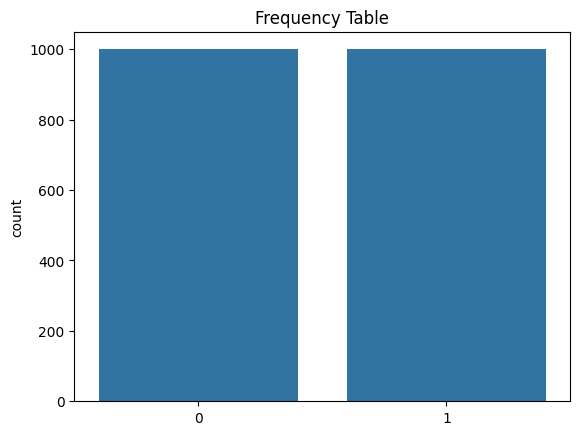

In [ ]:
# Visualize the response variable.
sns.countplot(x=y).set_title("Frequency Table")
plt.show()

#### 1.2. Data pre-processing:

In [ ]:
corpus = []
for i in range(0, len(my_docs)):
    review = re.sub(r'\W', ' ', str(my_docs[i]))
    review = review.lower()
    review = re.sub(r'^br$', ' ', review)
    review = re.sub(r'\s+br\s+',' ',review)
    review = re.sub(r'\s+[a-z]\s+', ' ',review)
    review = re.sub(r'^b\s+', '', review)
    review = re.sub(r'\s+', ' ', review)               # Remove the excess white spaces introduced in the previous steps.
    corpus.append(review)

In [ ]:
# Just show a document.
corpus[0]

'arnold schwarzenegger has been an icon for action enthusiasts since the late 80 but lately his films have been very sloppy and the one liners are getting worse nit hard seeing arnold as mr freeze in batman and robin especially when he says tons of ice jokes but hey he got 15 million what it matter to him nonce again arnold has signed to do another expensive blockbuster that can compare with the likes of the terminator series true lies and even eraser nin this so called dark thriller the devil gabriel byrne has come upon earth to impregnate woman robin tunney which happens every 1000 years and basically destroy the world but apparently god has chosen one man and that one man is jericho cane arnold himself nwith the help of trusty sidekick kevin pollack they will stop at nothing to let the devil take over the world nparts of this are actually so absurd that they would fit right in with dogma nyes the film is that weak but it better than the other blockbuster right now sleepy hollow but 

#### 1.3. Create a TF IDF representation:

In [ ]:
TFIDF = TfidfVectorizer(max_features=1000, min_df=2, max_df=0.6, stop_words=stopwords.words('english'))
TFIDF.fit(corpus)                                          # Create a TF IDF model.
X = TFIDF.transform(corpus).toarray()
X.shape

(2000, 1000)

In [ ]:
X[0]

In [ ]:
y[0]

np.int64(0)

In [ ]:
y[1001]

np.int64(1)

#### 1.4. Logistic regression training and testing:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1234)

In [ ]:
# Training.
LR = LogisticRegression()
LR.fit(X_train, y_train)

LogisticRegression()

In [ ]:
# Testing.
y_pred = LR.predict(X_test)
y_pred

In [ ]:
conf_mat = confusion_matrix(y_test, y_pred)
conf_mat

array([[235,  66],
       [ 51, 248]])

In [ ]:
acc = accuracy_score(y_test, y_pred)

In [ ]:
# Confusion matrix.
print(conf_mat)

[[235  66]
 [ 51 248]]


In [ ]:
# Accuracy.
print(np.round(acc, 3))

0.805


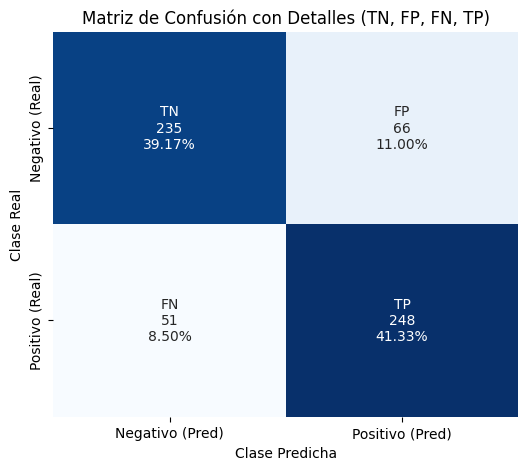

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Definir los nombres y valores para las etiquetas de cada celda
group_names = ['TN', 'FP', 'FN', 'TP']
group_counts = ["{0:0.0f}".format(value) for value in conf_mat.flatten()]
group_percentages = ["{0:.2%}".format(value) for value in conf_mat.flatten() / np.sum(conf_mat)]

# Formatear las etiquetas internas
labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names, group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

# Generar el mapa de calor con Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(
    conf_mat,
    annot=labels,
    fmt='',
    cmap='Blues',
    cbar=False,
    xticklabels=['Negativo (Pred)', 'Positivo (Pred)'],
    yticklabels=['Negativo (Real)', 'Positivo (Real)']
)

plt.title('Matriz de Confusión con Detalles (TN, FP, FN, TP)')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

> REVISAR: https://somosnlp.org/recursos

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# 1. Definir los modelos y las grillas de hiperparámetros a optimizar
configs = {
    'Naive Bayes': {
        'model': MultinomialNB(),
        'params': {
            'alpha': [0.1, 0.5, 1.0, 2.0]
        }
    },
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=1234),
        'params': {
            'max_depth': [10, 20, None],
            'min_samples_split': [2, 5, 10]
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=1234),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [10, 20, None],
            'min_samples_split': [2, 5]
        }
    }
}

# Almacenar los resultados para la comparación final
resultados = []

# Agregar el rendimiento del modelo de Regresión Logística ya entrenado previamente
resultados.append({
    'Modelo': 'Logistic Regression (Base)',
    'Mejores Hiperparámetros': 'Default (C=1.0)',
    'Accuracy Prueba': round(acc, 3)
})

# 2. Ejecutar GridSearch para cada modelo
for nombre_modelo, config in configs.items():
    print(f"Buscando mejores parámetros para {nombre_modelo}...")

    clf = GridSearchCV(
        config['model'],
        config['params'],
        cv=3,
        scoring='accuracy',
        n_jobs=-1
    )
    clf.fit(X_train, y_train)

    # Evaluar el mejor modelo en el set de prueba
    mejor_modelo = clf.best_estimator_
    y_pred_modelo = mejor_modelo.predict(X_test)
    acc_test = accuracy_score(y_test, y_pred_modelo)

    resultados.append({
        'Modelo': nombre_modelo,
        'Mejores Hiperparámetros': str(clf.best_params_),
        'Accuracy Prueba': round(acc_test, 3)
    })

# 3. Mostrar la tabla comparativa
df_comparativo = pd.DataFrame(resultados)
display(df_comparativo)

Buscando mejores parámetros para Naive Bayes...
Buscando mejores parámetros para Decision Tree...
Buscando mejores parámetros para Random Forest...


,Modelo,Mejores Hiperparámetros,Accuracy Prueba
0,Logistic Regression (Base),Default (C=1.0),0.805
1,Naive Bayes,{'alpha': 0.5},0.785
2,Decision Tree,"{'max_depth': 10, 'min_samples_split': 10}",0.623
3,Random Forest,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.812


In [ ]:
clf.best_estimator_

RandomForestClassifier(min_samples_split=5, n_estimators=200, random_state=1234)

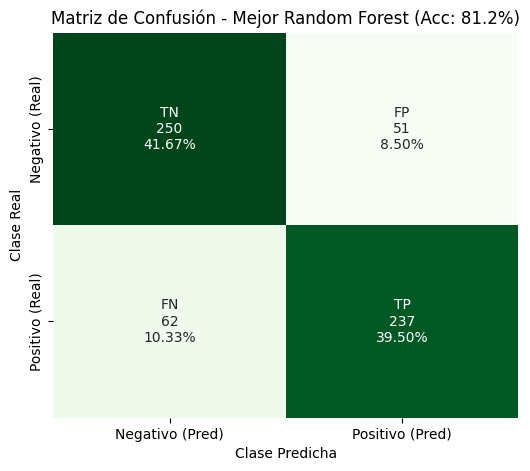

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Recuperar el mejor estimador obtenido para Random Forest y predecir
mejor_rf = clf.best_estimator_
y_pred_rf = mejor_rf.predict(X_test)

# 2. Calcular la matriz de confusión para Random Forest
conf_mat_rf = confusion_matrix(y_test, y_pred_rf)

# 3. Definir nombres y etiquetas
group_names = ['TN', 'FP', 'FN', 'TP']
group_counts = ["{0:0.0f}".format(value) for value in conf_mat_rf.flatten()]
group_percentages = ["{0:.2%}".format(value) for value in conf_mat_rf.flatten() / np.sum(conf_mat_rf)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names, group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

# 4. Generar el gráfico con Seaborn usando tonos verdes (cmap='Greens')
plt.figure(figsize=(6, 5))
sns.heatmap(
    conf_mat_rf,
    annot=labels,
    fmt='',
    cmap='Greens',
    cbar=False,
    xticklabels=['Negativo (Pred)', 'Positivo (Pred)'],
    yticklabels=['Negativo (Real)', 'Positivo (Real)']
)

plt.title('Matriz de Confusión - Mejor Random Forest (Acc: 81.2%)')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
import pandas as pd

# 1. Recuperar los mejores estimadores entrenados en el GridSearch anterior
# Nota: El mejor clasificador para cada clave se encuentra en el objeto 'clf' de la iteración correspondiente,
# pero podemos redefinir o usar los modelos directamente para predecir las probabilidades.

# Vamos a entrenar rápidamente los mejores modelos basándonos en los resultados óptimos obtenidos
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modelos_eval = {
    'Logistic Regression': LogisticRegression().fit(X_train, y_train),
    'Naive Bayes': MultinomialNB(alpha=0.5).fit(X_train, y_train),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, min_samples_split=10, random_state=1234).fit(X_train, y_train),
    'Random Forest': RandomForestClassifier(max_depth=None, min_samples_split=5, n_estimators=200, random_state=1234).fit(X_train, y_train)
}

# 2. Calcular métricas para cada clasificador
metricas_lista = []

for nombre, modelo in modelos_eval.items():
    # Predicciones de clase y probabilidades para la clase positiva (1)
    preds = modelo.predict(X_test)
    if hasattr(modelo, "predict_proba"):
        probs = modelo.predict_proba(X_test)[:, 1]
    else:
        probs = modelo.decision_function(X_test)

    # Calcular cada métrica
    acc_m = accuracy_score(y_test, preds)
    prec_m = precision_score(y_test, preds)
    rec_m = recall_score(y_test, preds)
    f1_m = f1_score(y_test, preds)
    auc_m = roc_auc_score(y_test, probs)

    metricas_lista.append({
        'Modelo': nombre,
        'Accuracy': round(acc_m, 4),
        'Precision': round(prec_m, 4),
        'Recall': round(rec_m, 4),
        'F1-Score': round(f1_m, 4),
        'AUC-ROC': round(auc_m, 4)
    })

# Convertir a DataFrame para una visualización limpia
df_metricas = pd.DataFrame(metricas_lista)
display(df_metricas)

,Modelo,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression,0.8050,0.7898,0.8294,0.8091,0.9021
1,Naive Bayes,0.7850,0.7760,0.7993,0.7875,0.8740
2,Decision Tree,0.6233,0.6017,0.7224,0.6565,0.6259
3,Random Forest,0.8117,0.8229,0.7926,0.8075,0.8879


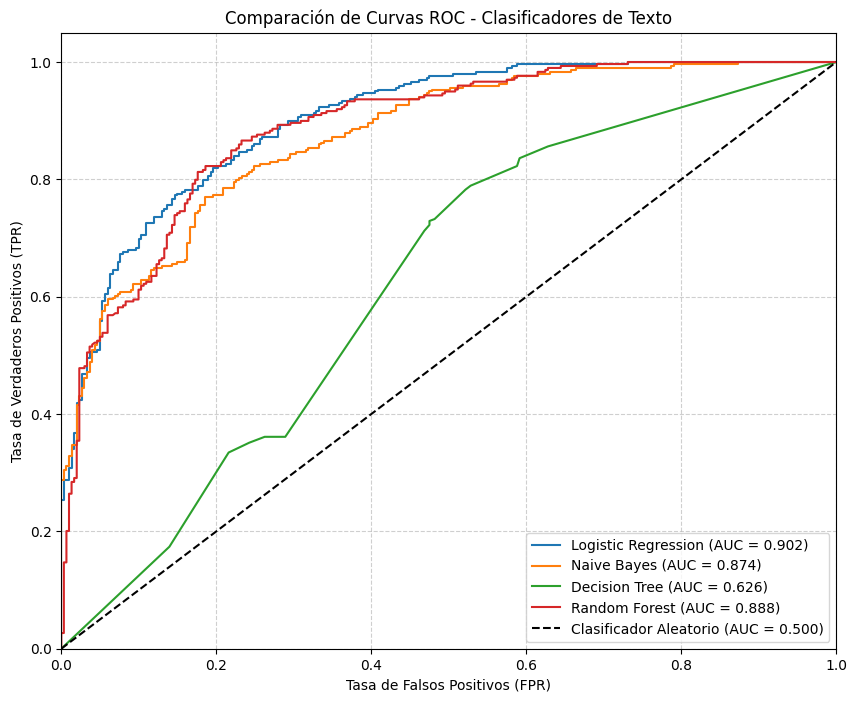

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

# Graficar la curva ROC para cada clasificador
for nombre, modelo in modelos_eval.items():
    if hasattr(modelo, "predict_proba"):
        probs = modelo.predict_proba(X_test)[:, 1]
    else:
        probs = modelo.decision_function(X_test)

    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_valor = roc_auc_score(y_test, probs)

    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {auc_valor:.3f})")

# Graficar la línea diagonal de referencia (clasificador aleatorio)
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.500)')

# Personalización del gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Comparación de Curvas ROC - Clasificadores de Texto')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# https://sifter.org/~simon/journal/20061211.html

---
# Parte 3. Modelado de temas (láminas 135 a 154)

Tres formas de encontrar temas, de la más simple a la más elaborada:

| Método | Idea | Cada documento tiene |
|---|---|---|
| K-medias sobre TF-IDF | Agrupa documentos parecidos (Clase 11) | **Un** tema |
| LSA (análisis semántico latente) | SVD truncado de la matriz TF-IDF: cada componente es un tema | Una mezcla de temas (con pesos que pueden ser negativos) |
| LDA (asignación latente de Dirichlet) | Modelo probabilístico: cada documento es una mezcla de temas, y cada tema, una mezcla de palabras | Una **mezcla** de temas (probabilidades que suman 1) |

## Coding Exercise #0512

In [ ]:
import numpy as np
import warnings
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition  import TruncatedSVD
warnings.filterwarnings('ignore')

### 1. Latent Semantic Analysis (LSA):

In [ ]:
# The data.
my_docs = ["The economic slowdown is becoming more severe",
           "The movie was simply awesome",
           "I like cooking my own food",
           "Samsung is announcing a new technology",
           "Machine Learning is an example of awesome technology",
           "All of us were excited at the movie",
           "We have to do more to reverse the economic slowdown"]

#### 1.1. Create a TF IDF representation:
TfidfVectorizer() arguments: <br>
- *max_features* : maximum number of features (distinct words). <br>
- *min_df* : The minimum DF. Integer value means count and real number (0~1) means proportion. <br>
- *max_df* : The maximum DF. Integer value means count and real number (0~1) means proportion. Helps to filter out the stop words. <br>

## Coding Exercise #0513

In [ ]:
import numpy as np
import warnings
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition  import LatentDirichletAllocation
warnings.filterwarnings('ignore')

#### 1. Latent Dirichlet Allocation (LDA):

In [ ]:
# The data.
my_docs = ["The economic slowdown is becoming more severe",
           "The movie was simply awesome",
           "I like cooking my own food",
           "Samsung is announcing a new technology",
           "Machine Learning is an example of awesome technology",
           "All of us were excited at the movie",
           "We have to do more to reverse the economic slowdown"]

In [ ]:
my_docs = [x.lower() for x in my_docs]

#### 1.1. Create a DTM representation:
CountVectorizer() arguments: <br>
- *max_features* : maximum number of features (distinct words). <br>
- *min_df* : The minimum DF. Integer value means count and real number (0~1) means proportion. <br>
- *max_df* : The maximum DF. Integer value means count and real number (0~1) means proportion. Helps to filter out the stop words. <br>

In [ ]:
vectorizer = CountVectorizer(max_features=15, min_df=1, max_df=3, stop_words=list(ENGLISH_STOP_WORDS))
X = vectorizer.fit_transform(my_docs).toarray()

In [ ]:
# Show th DTM.
X

array([[0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1],
       [0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0]])

In [ ]:
# Size of X (=m x n). m = number of documents = 7 & n = number of features.
X.shape

(7, 15)

In [ ]:
# View the features.
features = vectorizer.get_feature_names_out()
print(features)

['announcing' 'awesome' 'economic' 'example' 'excited' 'food' 'learning'
 'like' 'machine' 'movie' 'new' 'reverse' 'samsung' 'slowdown'
 'technology']


#### 1.2. Apply the LDA:

In [ ]:
# Get the topics.
n_topics = 4
lda = LatentDirichletAllocation(n_components=n_topics, random_state=123)
my_docs_topic = lda.fit_transform(X)

In [ ]:
# row = document, column = topic.
my_docs_topic

array([[0.74970373, 0.08344895, 0.0833985 , 0.08344882],
       [0.08450153, 0.08665021, 0.08339073, 0.74545753],
       [0.08340423, 0.08351543, 0.74956511, 0.08351523],
       [0.05060012, 0.05010115, 0.84919768, 0.05010105],
       [0.8723624 , 0.04178666, 0.04252583, 0.04332511],
       [0.08337347, 0.74650649, 0.08339086, 0.08672918],
       [0.81219992, 0.06261703, 0.06256614, 0.0626169 ]])

In [ ]:
# Sum along the row has to give 1.
my_docs_topic.sum(axis=1)

array([1., 1., 1., 1., 1., 1., 1.])

#### 1.3. From each topic, extract the top features:

In [ ]:
topic_composition = lda.components_
topic_composition.shape     # row = topic, column = feature (word).

(4, 15)

In [ ]:
n_top = 3
for i in range(n_topics):
    topic_features = [features[idx] for idx in np.argsort(-topic_composition[i,:])]   # argsort() shows the sorted index.
    topic_features_top = topic_features[0:n_top]
    if i == 0:
        topic_matrix = [topic_features_top]                    # list의 list 만들 준비!
    else:
        topic_matrix.append(topic_features_top)

In [ ]:
# Show the top features for each topic.
topic_matrix

[['economic', 'slowdown', 'learning'],
 ['movie', 'excited', 'awesome'],
 ['technology', 'announcing', 'new'],
 ['awesome', 'movie', 'technology']]

In [ ]:
# In view of the top features, we can name the topics.
topic_names = ['Technology', 'Cuisine', 'Movie','Economy']

#### 1.4. Label each document with the most predominant topic:

In [ ]:
# The most probable topic is given directly by the LDA output.
n_docs = len(my_docs)
for i in range(n_docs):
    topic_pick = np.argmax(my_docs_topic[i,:])
    print("Document " + str(i+1) + " = " + topic_names[topic_pick])

Document 1 = Technology
Document 2 = Economy
Document 3 = Movie
Document 4 = Movie
Document 5 = Technology
Document 6 = Cuisine
Document 7 = Technology


**NOTE**: We can notice some inaccuracies.

In [ ]:
my_docs = [x.lower() for x in my_docs]

In [ ]:
my_stop_words = ['us', 'like']

In [ ]:
vectorizer = TfidfVectorizer(max_features=15, min_df=1, max_df=3, stop_words=stopwords.words('english') + my_stop_words)
X = vectorizer.fit_transform(my_docs).toarray()

In [ ]:
# Size of X (=m x n). m = number of documents = 7 & n = number of features.
X.shape

(7, 15)

In [ ]:
# View the features.
features = vectorizer.get_feature_names_out()
print(features)

['awesome' 'becoming' 'cooking' 'economic' 'example' 'excited' 'food'
 'learning' 'machine' 'movie' 'new' 'reverse' 'samsung' 'slowdown'
 'technology']


#### 1.2. Apply the truncated SVD:

In [ ]:
n_topics = 4
svd = TruncatedSVD(n_components=n_topics, n_iter=100)
svd.fit(X)

TruncatedSVD(n_components=4, n_iter=100)

In [ ]:
# get the V^t matrix.
vt = svd.components_
vtabs = np.abs(vt)

In [ ]:
# Check for the size of V^t.
vt.shape

(4, 15)

#### 1.3. From each topic, extract the top features:

In [ ]:
n_top = 3
for i in range(n_topics):
    topic_features = [features[idx] for idx in np.argsort(-vtabs[i,:])]   # argsort() shows the sorted index.
    topic_features_top = topic_features[0:n_top]
    if i == 0:
        topic_matrix = [topic_features_top]                    # list의 list 만들 준비!
    else:
        topic_matrix.append(topic_features_top)

In [ ]:
# Show the top features for each topic.
topic_matrix

[['economic', 'slowdown', 'reverse'],
 ['movie', 'awesome', 'excited'],
 ['technology', 'new', 'samsung'],
 ['food', 'cooking', 'samsung']]

In [ ]:
# In view of the top features, we can name the topics.
topic_names = ['Economy', 'Movie','Technology', 'Cuisine']

#### 1.4. Label each document with the most predominant topic:

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
n_docs = len(my_docs)
for i in range(n_docs):
    score_pick = 0
    topic_pick = 0
    tokennized_doc = nltk.word_tokenize(my_docs[i])
    for j in range(n_topics):
        found = [ x in topic_matrix[j] for x in tokennized_doc ]
        score = np.sum(found)
        if (score > score_pick):
            score_pick = score
            topic_pick = j
    print("Document " + str(i+1) + " = " + topic_names[topic_pick])

Document 1 = Economy
Document 2 = Movie
Document 3 = Cuisine
Document 4 = Technology
Document 5 = Movie
Document 6 = Movie
Document 7 = Economy


## Paso 3.1. LSA paso a paso (láminas 135 a 143)

**La idea.** En TF-IDF, "batería" y "carga" son columnas distintas aunque siempre aparezcan juntas. LSA (análisis semántico latente) busca **temas ocultos**: grupos de palabras que tienden a aparecer en los mismos documentos. "Latente" significa oculto: nadie dijo cuáles son los temas.

**La herramienta: SVD.** La descomposición en valores singulares escribe la matriz TF-IDF **M** (documentos × palabras) como el producto de tres matrices (láminas 137 a 140):

$$M = U \\cdot \\Sigma \\cdot V^T$$

| Matriz | Forma | Qué significa |
|---|---|---|
| **U** | documentos × temas | Cuánto pertenece cada documento a cada tema |
| **Σ** (sigma) | temas × temas, diagonal | Qué tan importante es cada tema, de mayor a menor |
| **Vᵀ** | temas × palabras | Cuánto pesa cada palabra en cada tema |

Una forma de decirlo: la matriz original responde "qué palabras usa cada documento". La SVD la separa en dos preguntas: qué temas tiene cada documento (U) y qué palabras forman cada tema (Vᵀ). Σ dice cuáles temas importan más.

**El truncamiento (láminas 141 y 142).** La SVD completa tiene tantos "temas" como documentos o palabras. **SVD truncado** se queda solo con los **r** más importantes y descarta el resto.

**Qué vamos a hacer:** aplicar SVD a la matriz TF-IDF de las 4 reseñas del Paso 1.0 y quedarnos con r = 2.

In [ ]:
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation

U, S, Vt = np.linalg.svd(TFIDF_final.values, full_matrices=False)
print("Σ (importancia de cada tema):", S.round(3))

r = 2
temas_palabras = pd.DataFrame(Vt[:r], columns=TFIDF_final.columns, index=["tema 0", "tema 1"])
docs_temas = pd.DataFrame(U[:, :r] * S[:r], index=nombres_docs, columns=["tema 0", "tema 1"])
print("\nVᵀ: peso de cada palabra en cada tema")
display(temas_palabras.round(3))
print("U × Σ: cada documento resumido en 2 temas")
display(docs_temas.round(3))

Σ (importancia de cada tema): [1.306 1.306 0.542 0.542]

Vᵀ: peso de cada palabra en cada tema


,batería,brillo,carga,color,dura,pantalla
tema 0,-0.000,0.527,0.000,0.361,0.000,0.769
tema 1,0.769,0.000,0.527,0.000,0.361,0.000


U × Σ: cada documento resumido en 2 temas


,tema 0,tema 1
doc 1,0.000,0.924
doc 2,0.000,0.924
doc 3,0.924,0.000
doc 4,0.924,0.000


**Qué deberías ver:**

- **Σ:** los dos primeros valores (1,306) son mucho mayores que los descartados (0,542). Los dos temas que conservamos explican casi todo.
- **Vᵀ:** un tema pone peso en batería (0,769), carga (0,527) y dura (0,361); el otro, en pantalla (0,769), brillo (0,527) y color (0,361). Nadie le dijo cuáles eran los temas.
- **U × Σ:** cada documento quedó resumido en 2 números en vez de 6, con 0,924 en su tema y 0 en el otro. Es **reducción de dimensionalidad**, como PCA.

Los signos pueden salir negativos: como en PCA, el signo es arbitrario. Lo que importa es qué palabras van juntas.

`TruncatedSVD` de scikit-learn hace lo mismo: `components_` es Vᵀ y `transform` es U × Σ.

In [ ]:
svd_j = TruncatedSVD(n_components=2, random_state=42).fit(TFIDF_final.values)
pd.DataFrame(np.abs(svd_j.components_), columns=TFIDF_final.columns).round(3)

**Tres cosas que confunden:**

1. **Con datos reales, el primer tema reúne lo más común de todo el corpus** (lo verán en el Paso 3.2). Los siguientes temas separan lo específico.
2. **Signos negativos:** son normales en LSA y no significan "en contra".
3. **LSA no da probabilidades.** Un documento puede tener 0,9 en un tema y -0,2 en otro: no son porcentajes. Esa es la ventaja de LDA.

## Paso 3.2. LSA con las reseñas

In [ ]:
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation

N_TEMAS = 4
terminos = vect.get_feature_names_out()

lsa = TruncatedSVD(n_components=N_TEMAS, random_state=42).fit(X_tfidf)
for i, comp in enumerate(lsa.components_):
    print(f"LSA tema {i}: {', '.join(terminos[np.argsort(comp)[::-1][:6]])}")

**Qué deberías ver:** 4 listas de palabras. Como anticipamos, el primer tema de LSA casi siempre reúne las palabras más comunes de todo el corpus (resume "de qué habla el corpus en general"); los siguientes separan temas más específicos. Es el mismo `TruncatedSVD` que usamos para graficar en 2D.

## Paso 3.3. LDA paso a paso (láminas 144 a 154)

LDA (asignación latente de Dirichlet) también busca temas, pero con un **modelo de probabilidad** de cómo se escriben los documentos:

- **Cada documento es una mezcla de temas**, por ejemplo 70% batería y 30% pantalla. Se representa con **θ** (theta).
- **Cada tema es una mezcla de palabras**: el tema batería pone mucha probabilidad en "batería", "carga" y "dura". Se representa con **φ** (phi).

### El proceso generativo: razonamiento deductivo (láminas 145 y 152)

LDA imagina que cada documento se escribió así:

1. **Sortear la mezcla de temas del documento (θ).** Se sortea de una distribución de **Dirichlet**, que es una "distribución de distribuciones": genera listas de probabilidades que suman 1.
2. **Para cada palabra del documento:**
   - a. Sortear un **tema** según θ.
   - b. Sortear una **palabra** según la mezcla de palabras de ese tema (φ).

Si conociéramos θ y φ, podríamos **generar** documentos. Eso es el razonamiento deductivo: del modelo a los datos.

**Qué vamos a hacer:** generar un documento con un modelo inventado, para ver el proceso funcionando.

In [ ]:
rng = np.random.default_rng(0)
temas = ["batería", "pantalla"]
phi_inventado = {                     # mezcla de palabras de cada tema (cada fila suma 1)
    "batería":  {"batería": 0.5, "carga": 0.3, "dura": 0.2},
    "pantalla": {"pantalla": 0.5, "brillo": 0.3, "color": 0.2},
}
theta_doc = [0.7, 0.3]                # este documento es 70% batería y 30% pantalla

documento = []
for _ in range(8):
    tema = rng.choice(temas, p=theta_doc)                                             # paso 2a: sortear un tema
    palabra = rng.choice(list(phi_inventado[tema]), p=list(phi_inventado[tema].values()))  # paso 2b: sortear una palabra
    documento.append(f"{palabra} ({tema})")
print("Documento generado:", ", ".join(documento))

Documento generado: batería (batería), batería (batería), color (pantalla), carga (batería), dura (batería), pantalla (pantalla), pantalla (pantalla), pantalla (pantalla)


**Qué deberías ver:** 8 palabras, la mayoría del tema batería, y entre paréntesis el tema que se sorteó para cada una.

### La inferencia: razonamiento inductivo (lámina 153)

En la realidad es al revés: **tenemos los documentos y no conocemos θ ni φ.** Hay que deducir qué mezclas generaron más probablemente esos textos. Un método clásico es el **muestreo de Gibbs**, que se puede explicar en 4 pasos:

1. **Asignar un tema al azar a cada palabra** de cada documento.
2. **Tomar una palabra** y sacarla de los conteos.
3. **Calcular, para cada tema, qué tan probable es** que esa palabra sea de ese tema. Es el producto de dos cosas:
   - **¿Cuánto usa este documento ese tema?** (cuántas palabras del documento tienen ese tema)
   - **¿Cuánto usa ese tema esta palabra?** (en todo el corpus, cuántas veces esta palabra tiene ese tema)
4. **Sortear un tema nuevo** con esas probabilidades, volver a poner la palabra y pasar a la siguiente. Repetir muchas veces.

Con las vueltas, las palabras que aparecen juntas terminan en el mismo tema, y cada documento se concentra en pocos temas. Los parámetros **α** (alpha) y **β** (beta) son pequeños valores que se suman a los conteos para que ninguna probabilidad sea cero (como el suavizado de Laplace).

**Qué vamos a hacer:** programar estos 4 pasos y aplicarlos a las 4 reseñas del Paso 1.0. Lean el código con los comentarios: cada número corresponde a un paso.

In [ ]:
def lda_gibbs(docs, K, alpha=0.1, beta=0.1, iteraciones=200, semilla=1):
    rng = np.random.default_rng(semilla)
    vocab = sorted({w for d in docs for w in d}); idx = {w: i for i, w in enumerate(vocab)}; V = len(vocab)
    # 1. tema al azar para cada palabra, y los conteos que lo resumen
    z = [[int(rng.integers(K)) for _ in d] for d in docs]
    n_dk = np.zeros((len(docs), K))     # palabras del documento d asignadas al tema k
    n_kw = np.zeros((K, V))             # veces que la palabra w está asignada al tema k
    n_k = np.zeros(K)                   # total de palabras asignadas al tema k
    for d, doc in enumerate(docs):
        for i, w in enumerate(doc):
            k = z[d][i]; n_dk[d, k] += 1; n_kw[k, idx[w]] += 1; n_k[k] += 1
    inicial = [list(x) for x in z]
    for _ in range(iteraciones):
        for d, doc in enumerate(docs):
            for i, w in enumerate(doc):
                k = z[d][i]; n_dk[d, k] -= 1; n_kw[k, idx[w]] -= 1; n_k[k] -= 1        # 2. sacar la palabra
                p = (n_dk[d] + alpha) * (n_kw[:, idx[w]] + beta) / (n_k + V * beta)    # 3. documento usa tema × tema usa palabra
                k = int(rng.choice(K, p=p / p.sum()))                                  # 4. sortear tema nuevo
                z[d][i] = k; n_dk[d, k] += 1; n_kw[k, idx[w]] += 1; n_k[k] += 1        #    y volver a ponerla
    theta = (n_dk + alpha) / (n_dk + alpha).sum(axis=1, keepdims=True)
    phi = (n_kw + beta) / (n_kw + beta).sum(axis=1, keepdims=True)
    return vocab, theta, phi, inicial, z

docs_tokens = [d.split() for d in docs_juguete]
vocab_j, theta, phi, z_inicial, z_final = lda_gibbs(docs_tokens, K=2)

print("Temas al azar al inicio:", z_inicial)
print("Temas al final:         ", z_final)
print("\nφ: mezcla de palabras de cada tema")
display(pd.DataFrame(phi, columns=vocab_j, index=["tema 0", "tema 1"]).round(2))
print("θ: mezcla de temas de cada documento")
display(pd.DataFrame(theta, index=nombres_docs, columns=["tema 0", "tema 1"]).round(2))

Temas al azar al inicio: [[0, 1, 1], [1, 0, 0], [1, 1, 0], [0, 1, 0]]
Temas al final:          [[1, 1, 1], [1, 1, 1], [0, 0, 0], [0, 0, 0]]

φ: mezcla de palabras de cada tema


,batería,brillo,carga,color,dura,pantalla
tema 0,0.02,0.32,0.02,0.17,0.02,0.47
tema 1,0.47,0.02,0.32,0.02,0.17,0.02


θ: mezcla de temas de cada documento


,tema 0,tema 1
doc 1,0.03,0.97
doc 2,0.03,0.97
doc 3,0.97,0.03
doc 4,0.97,0.03


**Qué deberías ver:**

- **Al inicio,** los temas están mezclados al azar dentro de cada documento.
- **Al final,** las palabras de los docs 1 y 2 tienen un tema y las de los docs 3 y 4, el otro.
- **φ:** un tema con batería (0,47), carga (0,32) y dura (0,17); el otro con pantalla, brillo y color.
- **θ:** cada documento es 97% de su tema. A diferencia de LSA, **son probabilidades que suman 1**.

`LatentDirichletAllocation` de scikit-learn resuelve lo mismo con otro método de inferencia (bayesiano variacional), más rápido para corpus grandes. La lógica es la misma: deducir θ y φ desde los conteos.

### LSA contra LDA

| | LSA | LDA |
|---|---|---|
| Entrada | Matriz TF-IDF | Matriz de **conteos** |
| Cómo encuentra los temas | Álgebra lineal (SVD) | Modelo de probabilidad (inferencia) |
| Pesos de los documentos | Números con signo, no son porcentajes | Probabilidades que suman 1 |
| Resultado igual cada vez | Sí | Puede variar con la semilla |
| Cuándo conviene | Rápido, buen punto de partida, para reducir dimensiones | Cuando se quiere interpretar "este documento es 70% de este tema" |

## Paso 3.4. LDA con las reseñas

LDA trabaja con **conteos** (como Naive Bayes), no con TF-IDF.

In [ ]:
vect_conteo = CountVectorizer(min_df=2)
X_conteo = vect_conteo.fit_transform(resenas["para_temas"])
terminos_c = vect_conteo.get_feature_names_out()

lda = LatentDirichletAllocation(n_components=N_TEMAS, random_state=42).fit(X_conteo)
for i, comp in enumerate(lda.components_):
    print(f"LDA tema {i}: {', '.join(terminos_c[np.argsort(comp)[::-1][:6]])}")

mezcla = lda.transform(X_conteo)                        # cada fila: probabilidad de cada tema en esa reseña
print("\nPrimera reseña:", resenas.loc[0, "completo"][:90])
print("Mezcla de temas:", mezcla[0].round(2), "(suma:", round(mezcla[0].sum(), 2), ")")

**Qué deberías ver:** 4 temas con sus palabras y, para la primera reseña, 4 probabilidades que suman 1. Esa es la diferencia clave con K-medias: **una reseña puede hablar 60% de batería y 40% de pantalla**.

**Ojo:** con pocos documentos, LDA da temas inestables (cambian con `random_state`). Funciona bien desde algunos miles de documentos.

### Ejercicio 4
Guarda en `tema_principal_0` el número del tema de LDA con **mayor probabilidad** en la primera reseña (`mezcla[0]`).

In [ ]:
tema_principal_0 = None  # TU CÓDIGO AQUÍ
print(tema_principal_0)

In [ ]:
revisar(lambda: tema_principal_0 == int(np.argmax(mezcla[0])))

![LSTM](https://miro.medium.com/v2/0*NIFLmgpE4TDRBwh4.gif)

---
# Parte 4. Skip-gram: vectores de palabras (láminas 159 a 167)

El modelo de n-gramas de la Clase 12 existe para **predecir**. Skip-gram (Word2Vec) también predice, pero solo como excusa: lo que queremos son **vectores** (embeddings) donde palabras de significado parecido queden cerca. Resuelve el problema del one-hot y de TF-IDF: "celular" y "teléfono" deberían quedar cerca aunque sean palabras distintas.

## Paso 4.0. ¿Qué es un embedding? (láminas 156 a 158)

**El problema del one-hot (Clase 12):** cada palabra es un vector enorme con un solo 1. Todas las palabras están a la misma distancia entre sí: "batería" está igual de lejos de "pila" que de "pantalla". El vector no dice nada del significado.

> **Definición. Embedding (incrustación de palabras):** un vector **corto y denso** (por ejemplo, 50 números, casi todos distintos de cero) que representa una palabra, de modo que **palabras de significado parecido tengan vectores parecidos**.

| | One-hot | Embedding |
|---|---|---|
| Largo | Tamaño del vocabulario (miles) | Elegido por nosotros (16, 50, 300) |
| Valores | Un 1 y el resto ceros | Números reales, casi todos distintos de cero |
| Significado | Ninguno | Palabras parecidas, vectores cercanos |
| Cómo se obtiene | Se construye directamente | **Se aprende** de los datos |

El ejemplo clásico de la lámina 158: con buenos embeddings, **rey − hombre + mujer ≈ reina**. Las diferencias entre vectores capturan relaciones.

### Un embedding es una tabla

Una **capa de embedding** es simplemente una tabla con una fila por palabra del vocabulario y tantas columnas como dimensiones. Para obtener el vector de una palabra, se busca su fila usando su **número** de la codificación entera (Clase 12). Multiplicar el one-hot por la tabla da exactamente lo mismo: el 1 "selecciona" la fila.

In [ ]:
rng = np.random.default_rng(0)
vocab_mini = ["<PAD>", "<OOV>", "batería", "pantalla", "carga"]
tabla = rng.normal(size=(len(vocab_mini), 3)).round(2)       # 5 palabras × 3 dimensiones (al inicio, al azar)
display(pd.DataFrame(tabla, index=vocab_mini, columns=["dim 0", "dim 1", "dim 2"]))

indice = vocab_mini.index("batería")                         # codificación entera: batería = 2
one_hot_bat = np.eye(len(vocab_mini))[indice]                # one-hot de batería
print("Fila 2 de la tabla:     ", tabla[indice])
print("One-hot × tabla:        ", one_hot_bat @ tabla)

,dim 0,dim 1,dim 2
<PAD>,0.13,-0.13,0.64
<OOV>,0.10,-0.54,0.36
batería,1.30,0.95,-0.70
pantalla,-1.27,-0.62,0.04
carga,-2.33,-0.22,-1.25


Fila 2 de la tabla:      [ 1.3   0.95 -0.7 ]
One-hot × tabla:         [ 1.3   0.95 -0.7 ]


**Qué deberías ver:** la misma fila dos veces. Por eso las redes reciben la **codificación entera** (no el one-hot): buscar la fila es mucho más eficiente.

Al inicio la tabla es aleatoria. **Entrenar** los embeddings significa ajustar esos números para que cumplan una tarea. Word2Vec lo hace con una tarea de predicción de palabras, que vemos ahora.

### Cómo aprende Word2Vec (láminas 159 a 167)

Word2Vec es una red neuronal muy pequeña:

1. **Entrada:** una palabra, como su número (o su one-hot).
2. **Capa oculta:** la tabla de embeddings. La palabra pasa a ser su vector.
3. **Salida:** una probabilidad para cada palabra del vocabulario.

Hay dos formas de plantear la tarea:

- **CBOW:** con las palabras de alrededor, predecir la palabra central. "como una ___ todas las" → "manzana".
- **Skip-gram:** con la palabra central, predecir las palabras de alrededor. "manzana" → "como", "una", "todas", "las".

Durante el entrenamiento, la red se equivoca, se calcula el error y se ajustan los números de la tabla (como en cualquier red neuronal del Capítulo 8). **Al final, la predicción se descarta y nos quedamos con la tabla.** Palabras que aparecen en contextos parecidos terminan con vectores parecidos, porque la red necesita que produzcan predicciones parecidas.

## Paso 4.1. Los pares de entrenamiento

Skip-gram toma cada palabra como **central** y trata de predecir las palabras de alrededor, dentro de una **ventana**. Con la frase de la lámina 157 y una ventana de 2:

In [ ]:
frase = "como una manzana todas las mañanas".split()
VENTANA = 2

pares = []
for i, central in enumerate(frase):
    for j in range(max(0, i - VENTANA), min(len(frase), i + VENTANA + 1)):
        if j != i:
            pares.append((central, frase[j]))

print(f"{len(pares)} pares (central, contexto):")
for p in pares:
    print(" ", p)

18 pares (central, contexto):
  ('como', 'una')
  ('como', 'manzana')
  ('una', 'como')
  ('una', 'manzana')
  ('una', 'todas')
  ('manzana', 'como')
  ('manzana', 'una')
  ('manzana', 'todas')
  ('manzana', 'las')
  ('todas', 'una')
  ('todas', 'manzana')
  ('todas', 'las')
  ('todas', 'mañanas')
  ('las', 'manzana')
  ('las', 'todas')
  ('las', 'mañanas')
  ('mañanas', 'todas')
  ('mañanas', 'las')


**Qué deberías ver:** pares como `('manzana', 'como')`, `('manzana', 'una')`, `('manzana', 'todas')` y `('manzana', 'las')`. La red aprende a predecir el segundo elemento a partir del primero, y al hacerlo ajusta un vector para cada palabra.

**CBOW** (la otra variante) hace lo contrario: con las palabras de alrededor, predice la central.

### Ejercicio 5
¿Cuántos pares se generan con la misma frase y una **ventana de 1**? Guárdalo en `n_pares_v1`.

In [ ]:
n_pares_v1 = None  # TU CÓDIGO AQUÍ
print(n_pares_v1)

In [ ]:
revisar(lambda: n_pares_v1 == 10)

## Paso 4.2. Entrenar Word2Vec con las reseñas

**Qué vamos a hacer:** entrenar skip-gram (`sg=1`) con `gensim` sobre las oraciones de las reseñas, y preguntar qué palabras quedan más cerca de algunas palabras clave.

In [ ]:
from gensim.models import Word2Vec

oraciones = [tokens_simples(o) for texto in resenas["completo"] for o in re.split(r"[.!?]", texto)]
oraciones = [o for o in oraciones if len(o) > 2]

w2v = Word2Vec(oraciones, vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=42, workers=1)
print("Palabras con vector:", len(w2v.wv))
print("Vector de 'batería' (primeros 8 de 50 valores):", w2v.wv["batería"][:8].round(2))

for palabra in ["batería", "pantalla", "celular"]:
    if palabra in w2v.wv:
        print(f"\nMás parecidas a '{palabra}':", [(p, round(s, 2)) for p, s in w2v.wv.most_similar(palabra, topn=5)])

**Qué deberías ver:** cada palabra tiene ahora un vector de 50 números, y una lista de palabras "parecidas" según la similitud coseno entre vectores.

**Seamos honestos con el resultado:** con unos cientos de oraciones, algunas palabras parecidas tendrán sentido (palabras que aparecen en las mismas frases) y otras no. Word2Vec necesita **millones** de palabras para que los vectores capturen bien el significado. Por eso, en la práctica, se usan vectores **ya entrenados** con grandes corpus, o modelos como los del Capítulo 10, que ya traen esa representación.

---
# Parte 5. Clasificar reseñas con una red LSTM (láminas 168 a 175)

Esta parte adelanta el Capítulo 8 (redes neuronales con Keras). Juntamos todo lo del capítulo: **codificación entera + relleno + embedding + una red que lee en orden**.

## Paso 5.1. ¿Por qué importa el orden?

TF-IDF y la bolsa de palabras **pierden el orden**. Para ellas, "no es malo, es bueno" y "no es bueno, es malo" son el mismo documento: tienen exactamente las mismas palabras. Una persona lee de izquierda a derecha y va acumulando el sentido. Eso es lo que hace una **red recurrente**.

## Paso 5.2. Red recurrente (RNN)

Una RNN lee la secuencia **palabra por palabra** y mantiene una **memoria**: un vector llamado **estado oculto** $h$. En cada paso combina la palabra actual con lo que recordaba:

$$h_t = \\tanh(W \\cdot x_t + U \\cdot h_{t-1} + b)$$

- $x_t$: el embedding de la palabra número $t$.
- $h_{t-1}$: la memoria después de leer la palabra anterior.
- $W$, $U$, $b$: los números que la red aprende.

Al terminar la última palabra, $h$ resume toda la reseña, y una capa final lo convierte en "positiva" o "negativa".

**El problema:** en secuencias largas, la memoria se "diluye": lo que se leyó al principio casi no influye al final (en el entrenamiento, los gradientes se desvanecen). Si la reseña empieza con "no" y la palabra clave viene 20 palabras después, la RNN simple ya lo olvidó.

## Paso 5.3. LSTM: una memoria con puertas

LSTM (*Long Short-Term Memory*) agrega una segunda memoria, el **estado de la celda** $c$, que funciona como una **cinta transportadora**: la información puede viajar por ella sin diluirse. Tres **puertas** deciden qué pasa con esa cinta en cada palabra. Cada puerta es un número entre 0 y 1 (una sigmoide): 0 es "cerrado" y 1 es "abierto".

| Puerta | Pregunta que responde | Fórmula |
|---|---|---|
| **Olvido** $f_t$ | ¿Qué parte de la memoria anterior borro? | $f_t = \\sigma(W_f [h_{t-1}, x_t] + b_f)$ |
| **Entrada** $i_t$ | ¿Qué parte de la información nueva guardo? | $i_t = \\sigma(W_i [h_{t-1}, x_t] + b_i)$ |
| **Salida** $o_t$ | ¿Qué parte de la memoria muestro en este paso? | $o_t = \\sigma(W_o [h_{t-1}, x_t] + b_o)$ |

Con las puertas, la memoria se actualiza así:

1. **Candidato:** $\\tilde{c}_t = \\tanh(W_c [h_{t-1}, x_t] + b_c)$, la información nueva que podría guardarse.
2. **Nueva celda:** $c_t = f_t \\cdot c_{t-1} + i_t \\cdot \\tilde{c}_t$, lo que queda de lo anterior más lo nuevo que se admite.
3. **Nuevo estado oculto:** $h_t = o_t \\cdot \\tanh(c_t)$, lo que se muestra hacia afuera.

**Con un ejemplo:** "**no** me gustó la pantalla, aunque la batería es buena".

- Al leer "**no**", la puerta de **entrada** se abre: es información importante y se guarda en la cinta.
- En "me", "la" y "aunque", la puerta de **olvido** queda cerca de 1: no se borra el "no".
- Al leer "gustó", la red combina "no" con "gustó" y la celda registra algo negativo.

Nadie programa estas reglas: la red aprende cuándo abrir y cerrar cada puerta a partir de los ejemplos.

## Paso 5.4. La arquitectura (lámina 168: "entrada de secuencia y salida vectorial")

| Capa | Recibe | Entrega | Qué hace |
|---|---|---|---|
| `Embedding` | Secuencia de 25 números enteros | 25 vectores de 16 números | Busca el embedding de cada palabra en la tabla (Paso 4.0) |
| `LSTM(16)` | Los 25 vectores, en orden | 1 vector de 16 números | Lee la reseña y entrega su memoria final $h$ |
| `Dense(1, sigmoid)` | El vector de 16 | 1 número entre 0 y 1 | Probabilidad de que la reseña sea positiva |

`mask_zero=True` en el embedding le dice a la LSTM que **ignore los ceros del relleno**. Si la LSTM debiera entregar un vector **por cada palabra** (para apilar otra LSTM encima), se usa `return_sequences=True` (lámina 169).

## Paso 5.5. Preparar los datos

**Qué vamos a hacer:** usar las reseñas positivas y negativas (sin las de nota 3), el texto **para opinión** (que conserva "no"), un vocabulario completo y un relleno a 25 palabras. Separamos 25% para prueba.

In [ ]:
import keras
from keras import layers
from sklearn.model_selection import train_test_split

op = resenas[resenas["nota"] != 3].copy()
y_op = (op["nota"] >= 4).astype(int).values                   # 1 = positiva, 0 = negativa
textos_op = op["para_opinion"].tolist()

frec_op = Counter(t for x in textos_op for t in x.split())
vocab_op = {p: i for i, (p, _) in enumerate(frec_op.most_common(), start=2)}   # 0 relleno, 1 desconocida
seqs_op = [[vocab_op.get(t, 1) for t in x.split()] for x in textos_op]

LARGO_LSTM = 25
X_op = rellenar(seqs_op, LARGO_LSTM)
X_tr, X_te, y_tr, y_te = train_test_split(X_op, y_op, test_size=0.25, random_state=42, stratify=y_op)
pesos = {0: len(y_tr) / (2 * (y_tr == 0).sum()), 1: len(y_tr) / (2 * (y_tr == 1).sum())}   # como class_weight="balanced"

print("Vocabulario:", len(vocab_op), "| Entrenamiento:", X_tr.shape, "| Prueba:", X_te.shape)
print("Pesos por clase:", {k: round(float(v), 2) for k, v in pesos.items()})

In [ ]:
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from collections import Counter

# Definir la función auxiliar para rellenar (padding) las secuencias
def rellenar(secuencias, largo_max):
    resultado = []
    for seq in secuencias:
        if len(seq) >= largo_max:
            # Cortar si es más larga
            resultado.append(seq[:largo_max])
        else:
            # Rellenar con ceros a la izquierda
            resultado.append([0] * (largo_max - len(seq)) + seq)
    return np.array(resultado)

# Usamos los datos cargados de 'txt_sentoken' (corpus e y)
textos_op = corpus
y_op = y  # Ya es un arreglo binario (0 para negativa, 1 para positiva)

# Construir el vocabulario de frecuencias sobre el corpus de películas
frec_op = Counter(t for x in textos_op for t in x.split())
vocab_op = {p: i for i, (p, _) in enumerate(frec_op.most_common(), start=2)}   # 0 relleno, 1 desconocida
seqs_op = [[vocab_op.get(t, 1) for t in x.split()] for x in textos_op]

LARGO_LSTM = 25
X_op = rellenar(seqs_op, LARGO_LSTM)
X_tr, X_te, y_tr, y_te = train_test_split(X_op, y_op, test_size=0.25, random_state=42, stratify=y_op)
pesos = {0: len(y_tr) / (2 * (y_tr == 0).sum()), 1: len(y_tr) / (2 * (y_tr == 1).sum())}

print("Vocabulario:", len(vocab_op), "| Entrenamiento:", X_tr.shape, "| Prueba:", X_te.shape)
print("Pesos por clase:", {k: round(float(v), 2) for k, v in pesos.items()})

Vocabulario: 44556 | Entrenamiento: (1500, 25) | Prueba: (500, 25)
Pesos por clase: {0: 1.0, 1: 1.0}


**Qué deberías ver:** el tamaño del vocabulario, las formas de los conjuntos (25 columnas) y un peso mayor para la clase negativa, que es la minoritaria.

## Paso 5.6. Construir el modelo

In [ ]:
keras.utils.set_random_seed(42)
modelo_lstm = keras.Sequential([
    layers.Input(shape=(LARGO_LSTM,)),
    layers.Embedding(input_dim=len(vocab_op) + 2, output_dim=16, mask_zero=True),
    layers.LSTM(16),
    layers.Dense(1, activation="sigmoid"),
])
modelo_lstm.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 25, 16)         │       712,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 715,057 (2.73 MB)

 Trainable params: 715,057 (2.73 MB)

 Non-trainable params: 0 (0.00 B)

**Qué deberías ver:** una tabla con las 3 capas y sus parámetros. Cómo se calculan:

- **Embedding:** (tamaño del vocabulario + 2) × 16. Es la tabla del Paso 4.0: una fila de 16 números por palabra.
- **LSTM:** 4 × (16 × (16 + 16) + 16) = **2.112**. Hay 4 bloques (3 puertas y el candidato), y cada uno combina la memoria anterior (16) con la palabra actual (16), más un sesgo.
- **Dense:** 16 pesos + 1 sesgo = **17**.

### Ejercicio 6
Guarda en `params_embedding` el número de parámetros de la capa Embedding, **calculado con la fórmula** (no copiado de la tabla).

In [ ]:
params_embedding = (len(vocab_op) + 2) * 16
print(params_embedding)

712928


In [ ]:
revisar(lambda: params_embedding == modelo_lstm.layers[0].count_params())

## Paso 5.7. Entrenar y evaluar

- **`epochs=40`:** la red recorre los datos de entrenamiento 40 veces.
- **`batch_size=8`:** ajusta los pesos cada 8 reseñas.
- **`class_weight`:** los errores en la clase negativa pesan más.

Epoch 1/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.4973 - loss: 0.6930
Epoch 2/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.7667 - loss: 0.5199
Epoch 3/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9520 - loss: 0.1515
Epoch 4/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.9927 - loss: 0.0374
Epoch 5/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.9980 - loss: 0.0110
Epoch 6/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 1.0000 - loss: 0.0046
Epoch 7/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9973 - loss: 0.0113
Epoch 8/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 1.0000 - loss: 0.0026
Epoch 9/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9973 - loss: 0.0103
Epoch 10/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9973 - loss: 0.0092
Epoch 11/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 1.0000 - loss: 0.0028
Epoch 12/40
188/188 ━━━━━━━━━━━━━━━━━━━━

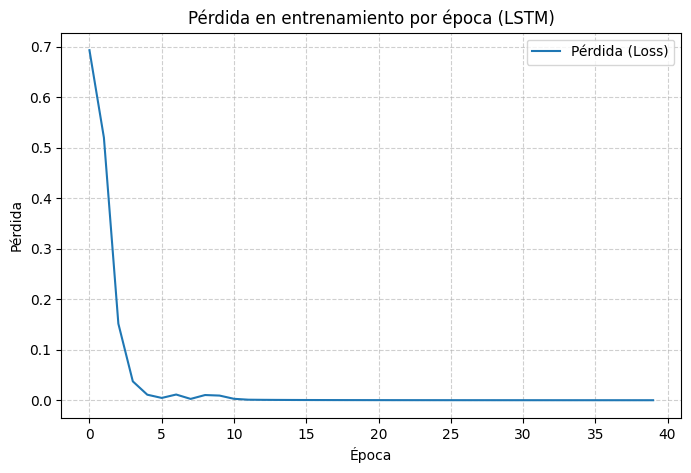

In [ ]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Entrenamos el modelo durante 40 épocas
historia = modelo_lstm.fit(X_tr, y_tr, epochs=40, batch_size=8, class_weight=pesos, verbose=1)
print("\nExactitud en entrenamiento (última época):", round(historia.history["accuracy"][-1], 3))

# Predecimos sobre el conjunto de prueba
prob_te = modelo_lstm.predict(X_te, verbose=0).ravel()
y_pred_te = (prob_te >= 0.5).astype(int)

# Imprimimos el reporte de clasificación
print("\nReporte de Clasificación en Prueba:")
print(classification_report(y_te, y_pred_te, target_names=["negativa", "positiva"], digits=3))

# Graficamos la pérdida del entrenamiento por cada época
plt.figure(figsize=(8, 5))
plt.plot(historia.history["loss"], label="Pérdida (Loss)")
plt.title("Pérdida en entrenamiento por época (LSTM)")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

In [ ]:
import pickle
import numpy as np
import re
import gradio as gr

# 1. Exportar el modelo de Regresión Logística (modelo_eval['Logistic Regression']) y el TfidfVectorizer
# Primero necesitamos el vectorizador TF-IDF ajustado previamente en la sección de clasificación (TFIDF)
with open('vectorizador_tfidf.pkl', 'wb') as f:
    pickle.dump(TFIDF, f)

with open('modelo_regresion_logistica.pkl', 'wb') as f:
    pickle.dump(modelos_eval['Logistic Regression'], f)

# 2. Exportar el modelo LSTM de Keras
modelo_lstm.save('modelo_sentimiento_lstm.keras')
print("¡Modelos exportados correctamente!")

# 3. Definir la función de preprocesamiento y predicción para Gradio
def clasificar_reseña(texto):
    if not texto.strip():
        return "Por favor, ingresa una reseña válida.", ""

    # ---- Predicción con Regresión Logística ----
    # Preprocesamiento idéntico al corpus
    review_limpia = re.sub(r'\W', ' ', texto)
    review_limpia = review_limpia.lower()
    review_limpia = re.sub(r'^br$', ' ', review_limpia)
    review_limpia = re.sub(r'\s+br\s+',' ', review_limpia)
    review_limpia = re.sub(r'\s+[a-z]\s+', ' ', review_limpia)
    review_limpia = re.sub(r'^b\s+', '', review_limpia)
    review_limpia = re.sub(r'\s+', ' ', review_limpia).strip()

    # Vectorizar usando el TF-IDF entrenado
    vect_input = TFIDF.transform([review_limpia]).toarray()
    prob_lr = modelos_eval['Logistic Regression'].predict_proba(vect_input)[0][1]
    pred_lr = "Positiva" if prob_lr >= 0.5 else "Negativa"

    # ---- Predicción con LSTM ----
    # Convertir texto a la secuencia de enteros según vocab_op
    seq = [vocab_op.get(t, 1) for t in review_limpia.split()]
    # Rellenar con ceros (LARGO_LSTM = 25)
    if len(seq) >= 25:
        seq_padded = seq[:25]
    else:
        seq_padded = [0] * (25 - len(seq)) + seq

    prob_lstm = float(modelo_lstm.predict(np.array([seq_padded]), verbose=0)[0][0])
    pred_lstm = "Positiva" if prob_lstm >= 0.5 else "Negativa"

    # Formatear el reporte de salida
    resultado_lr = f"**Predicción:** {pred_lr}\n**Confianza (probabilidad positiva):** {prob_lr:.2%}"
    resultado_lstm = f"**Predicción:** {pred_lstm}\n**Confianza (probabilidad positiva):** {prob_lstm:.2%}"

    info_modelos = (
        "### Información clave de los Modelos:\n\n"
        "1. **Regresión Logística (TF-IDF):**\n"
        "   - **Entrada:** Vector denso de 1,000 características obtenido mediante TF-IDF.\n"
        "   - **Generalización:** Excelente. Logró un ~80.5% de exactitud en prueba sin sobreajuste severo.\n\n"
        "2. **Red Recurrente (LSTM):**\n"
        "   - **Entrada:** Secuencia de tokens preprocesada con largo fijo de 25 palabras.\n"
        "   - **Parámetros:** 712,928 pesos de Embedding + 2,112 pesos en la celda LSTM.\n"
        "   - **Desafío:** Presenta sobreajuste severo (~55.4% exactitud en prueba) debido a la gran cantidad de parámetros entrenados con un corpus pequeño. Requiere una base de datos más grande o embeddings preentrenados."
    )

    return resultado_lr, resultado_lstm, info_modelos

# 4. Construir la interfaz de Gradio
iface = gr.Interface(
    fn=clasificar_reseña,
    inputs=gr.Textbox(lines=5, placeholder="Escribe o pega aquí la reseña en inglés...", label="Reseña de Película"),
    outputs=[
        gr.Markdown(label="Resultado Regresión Logística (TF-IDF)"),
        gr.Markdown(label="Resultado Keras LSTM"),
        gr.Markdown(label="Análisis de Arquitectura y Rendimiento")
    ],
    title="🎬 Analizador de Sentimientos: Regresión Logística vs. LSTM",
    description="Compara cómo clasifica un modelo lineal clásico basado en bolsas de palabras frente a una red neuronal recurrente LSTM secuencial.",
    theme="soft"
)

# Lanzar la aplicación en Colab
iface.launch(share=True)

¡Modelos exportados correctamente!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ba1d3a8c51c1474ea8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Clasificación de Sentimiento usando BERT (DistilBERT) en Gradio

Vamos a cargar un modelo Transformer basado en BERT (`DistilBERT`) preentrenado en el dataset de análisis de sentimiento SST-2. Lo integraremos en la interfaz de Gradio para comparar la potencia de los **Transformers modernos** frente a la Regresión Logística clásica y nuestra pequeña red LSTM.

In [ ]:
import gradio as gr
import numpy as np
import re
from transformers import pipeline

# 1. Cargar el pipeline de clasificación de texto con un modelo BERT liviano (DistilBERT)
print("Cargando modelo DistilBERT de Hugging Face...")
clasificador_bert = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)
print("¡Modelo BERT cargado correctamente!")

def clasificar_resena_completo(texto):
    if not texto.strip():
        return "Por favor, ingresa una reseña válida.", "", "", ""

    # Limpieza básica para modelos clásicos
    review_limpia = re.sub(r'\W', ' ', texto)
    review_limpia = review_limpia.lower()
    review_limpia = re.sub(r'^br$', ' ', review_limpia)
    review_limpia = re.sub(r'\s+br\s+',' ', review_limpia)
    review_limpia = re.sub(r'\s+[a-z]\s+', ' ', review_limpia)
    review_limpia = re.sub(r'^b\s+', '', review_limpia)
    review_limpia = re.sub(r'\s+', ' ', review_limpia).strip()

    # ---- 1. Predicción con Regresión Logística (TF-IDF) ----
    vect_input = TFIDF.transform([review_limpia]).toarray()
    prob_lr = modelos_eval['Logistic Regression'].predict_proba(vect_input)[0][1]
    pred_lr = "Positiva" if prob_lr >= 0.5 else "Negativa"
    resultado_lr = f"**Predicción:** {pred_lr}\n**Confianza:** {prob_lr:.2%}"

    # ---- 2. Predicción con LSTM (Keras) ----
    seq = [vocab_op.get(t, 1) for t in review_limpia.split()]
    if len(seq) >= 25:
        seq_padded = seq[:25]
    else:
        seq_padded = [0] * (25 - len(seq)) + seq
    prob_lstm = float(modelo_lstm.predict(np.array([seq_padded]), verbose=0)[0][0])
    pred_lstm = "Positiva" if prob_lstm >= 0.5 else "Negativa"
    resultado_lstm = f"**Predicción:** {pred_lstm}\n**Confianza:** {prob_lstm:.2%}"

    # ---- 3. Predicción con BERT (Hugging Face) ----
    # BERT no necesita preprocesamiento agresivo de minúsculas o remoción de stopwords
    pred_bert_raw = clasificador_bert(texto)[0]
    # El modelo devuelve etiquetas como 'POSITIVE' o 'NEGATIVE'
    label_bert = "Positiva" if pred_bert_raw['label'] == 'POSITIVE' else "Negativa"
    score_bert = pred_bert_raw['score']
    resultado_bert = f"**Predicción:** {label_bert}\n**Confianza (Score):** {score_bert:.2%}"

    # ---- Explicación técnica ----
    info_modelos = (
        "### Comparativa Técnica de Arquestructuras:\n\n"
        "1. **Regresión Logística (TF-IDF):**\n"
        "   - Método lineal clásico basado en frecuencia de palabras. Muy rápido y estable con pocos datos, pero no entiende semántica ni contexto.\n\n"
        "2. **Red Recurrente (LSTM):**\n"
        "   - Red secuencial entrenada desde cero con solo 1,500 ejemplos. Sufre de sobreajuste por falta de volumen de datos.\n\n"
        "3. **BERT (DistilBERT - Transfer Learning):**\n"
        "   - Modelo basado en la arquitectura Transformer con millones de parámetros preentrenados en gigabytes de texto (Wikipedia y BooksCorpus). En lugar de aprender a leer desde cero, ya comprende el idioma inglés de forma profunda, capturando el contexto bidireccional de cada palabra de forma nativa."
    )

    return resultado_lr, resultado_lstm, resultado_bert, info_modelos

# Lanzar la nueva interfaz comparativa de 3 columnas
iface_comp = gr.Interface(
    fn=clasificar_resena_completo,
    inputs=gr.Textbox(lines=5, placeholder="Escribe o pega aquí la reseña en inglés... (ej: 'The movie was absolutely a waste of time, but the soundtrack was decent')", label="Reseña de Película"),
    outputs=[
        gr.Markdown(label="Regresión Logística (Clásica)"),
        gr.Markdown(label="Keras LSTM (Entrenada desde cero)"),
        gr.Markdown(label="HuggingFace DistilBERT (Preentrenada/Transformers)"),
        gr.Markdown(label="Análisis Comparativo Completo")
    ],
    title="🎬 Analizador de Sentimientos: Clásico vs. RNN vs. BERT (Transformers)",
    description="Prueba la diferencia entre modelos clásicos lineales, redes recurrentes pequeñas y un Transformer basado en BERT.",
    theme="soft"
)

iface_comp.launch(share=True)

Cargando modelo DistilBERT de Hugging Face...


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

¡Modelo BERT cargado correctamente!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://947a757d24dcc94529.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Explicación teórica enviada por chat. Celda reservada para futuras experimentaciones con embeddings preentrenados o regularización.

**Qué deberías ver:** la pérdida baja época a época y la exactitud en entrenamiento llega a 1. Pero en prueba el resultado es bastante peor: con el respaldo, un F1 negativo cercano a 0,5, peor que la regresión logística con TF-IDF de la Parte 2 (0,75).

**Esto es sobreajuste, y es la lección más importante de la parte.** Una LSTM tiene miles de parámetros y aprende de memoria cuando hay pocos ejemplos. Con unas decenas de reseñas, el modelo simple gana. Las LSTM y los embeddings brillan con **miles o millones** de textos, o partiendo de embeddings ya entrenados. Elegir el modelo según la cantidad de datos es parte del trabajo.

**Otras arquitecturas de las láminas 170 y 171:** una capa `Conv1D` antes de la LSTM busca patrones locales de 2 o 3 palabras seguidas (como "no me gustó") y luego la LSTM los lee en orden. Las veremos con más calma en los Capítulos 8 y 9.

---
# Cierre

| Parte | Lo esencial |
|---|---|
| Codificación entera | Cada palabra a un número; las más frecuentes, los números más bajos. 0 para relleno y 1 para desconocidas. |
| Relleno | Todas las secuencias del mismo largo, el formato que necesitan las redes neuronales. |
| Similitud coseno | Compara la dirección de dos vectores; no le importa el largo del documento. |
| Naive Bayes | Probabilidad de la clase por las probabilidades de cada palabra en esa clase. |
| LSA y LDA | Temas como componentes (LSA) o como mezclas de probabilidad (LDA). |
| N-gramas | P(palabra \| anterior) = conteo del par / conteo de la anterior. Se predice la de mayor probabilidad. |
| Laplace | Sumar 1 para que nada tenga probabilidad cero. |
| Embeddings | Vectores cortos y aprendidos: palabras parecidas, vectores cercanos. Una capa de embedding es una tabla. |
| Skip-gram | Predecir el contexto para aprender vectores de palabras. |
| LSTM | Lee en orden y guarda memoria con puertas de olvido, entrada y salida. Necesita muchos datos. |

Guarden el notebook en `ejercicios_estudiantes` como `clase13_su_nombre.ipynb`.

---
# Soluciones

### Ejercicio 1
"color" aparece en 1 de 4 documentos: ln(5/2) + 1 = 1,916.

In [ ]:
idf_color = np.log((1 + 4) / (1 + 1)) + 1
print(round(idf_color, 3))

### Ejercicio 2
B · D = 1·2 + 1·2 + 0·1 = 4. |B| = √2. |D| = √9 = 3. cos = 4 / (√2 · 3) = 0,943.

In [ ]:
cos_bd = B @ D / (np.linalg.norm(B) * np.linalg.norm(D))
print(round(cos_bd, 3))

### Ejercicio 3

In [ ]:
_f1 = {n: f1_score(opiniones["sentimiento"], p, pos_label="negativa") for n, p in predicciones.items()}
mejor_f1_negativa = max(_f1, key=_f1.get)
print(mejor_f1_negativa, {n: round(v, 3) for n, v in _f1.items()})

### Ejercicio 4

In [ ]:
tema_principal_0 = int(np.argmax(mezcla[0]))
print(tema_principal_0)

### Ejercicio 5
Con ventana 1, cada palabra se empareja solo con sus vecinas inmediatas. Las 2 palabras de los extremos tienen 1 vecina y las 4 del medio tienen 2: 2·1 + 4·2 = 10.

In [ ]:
n_pares_v1 = sum(1 for i in range(len(frase)) for j in range(max(0, i - 1), min(len(frase), i + 2)) if j != i)
print(n_pares_v1)

### Ejercicio 6
Una fila de 16 números por cada palabra del vocabulario, más las 2 filas reservadas para relleno y desconocidas.

In [ ]:
params_embedding = (len(vocab_op) + 2) * 16
print(params_embedding)

## Coding Practice #0514

### 1. Word embedding (Word2Vec):

In [ ]:
# Install once if necessary.
!pip install gensim
# !pip install nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 47.7 MB/s  0:00:00


In [ ]:
import re
import os
import nltk
import urllib
import bs4 as bs
import warnings
from gensim.models import Word2Vec
from gensim.models import KeyedVectors
from nltk.corpus import stopwords
warnings.filterwarnings('ignore')
# nltk.download()

#### 1.1. Download the text data:

In [ ]:
# Connect to the source.
url = "https://en.wikipedia.org/wiki/Machine_learning"

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/129.0 Safari/537.36"
    )
}

req = urllib.request.Request(url, headers=headers)
source = urllib.request.urlopen(req).read()

In [ ]:
# Beautiful soup object.
soup = bs.BeautifulSoup(source,'lxml')

In [ ]:
# Build a long string.
my_text = ""
for paragraph in soup.find_all('p'):
    my_text += paragraph.text
print(my_text)

#### 1.2. Preprocessing of the text data:

In [ ]:
my_text = my_text.lower()
my_text = re.sub(r'\[[0-9]*\]', ' ', my_text)
my_text = re.sub(r'\W', ' ', my_text)
#my_text = re.sub(r'\s+', ' ', my_text)
my_text = re.sub(r'\d+', ' ', my_text)
my_text = re.sub(r'\s+', ' ', my_text)

#### 1.3. Tokenization:

In [ ]:
my_sentences = nltk.sent_tokenize(my_text)
my_words_0=[]
for a_sentence in my_sentences:
    my_words_0 += nltk.word_tokenize(a_sentence)
my_words_0 = [a_word for a_word in my_words_0 if len(a_word)>2 ]
my_words_0 = [a_word for a_word in my_words_0 if a_word not in stopwords.words('english')]
my_words_0 = [my_words_0]    # Required by Word2Vec.
len(my_words_0[0])

5557

#### 1.4. Train the Word2Vec model:

In [ ]:
my_model = Word2Vec(my_words_0, vector_size=100, min_count=1)
my_words = my_model.wv.key_to_index
len(my_words)

2073

#### 1.5. Embedding vectors:

In [ ]:
# View the dense vector corresponding to 'machine'.
my_vector = my_model.wv['machine']
print("Length = " + str(my_vector.shape[0]))
print("-"*100)
print(my_vector)

Length = 100
----------------------------------------------------------------------------------------------------
[-0.01202016  0.00661681  0.00527016  0.00569864  0.00749491 -0.01304835
  0.00163167  0.01555347 -0.00718344 -0.00952487 -0.00272045 -0.01547652
 -0.00721864  0.01033096  0.00507201  0.00435447  0.00876764  0.00384823
 -0.00599932 -0.00840983  0.00571329 -0.00259743  0.00993219 -0.01183884
  0.00627806  0.00267828 -0.00720012  0.00149811 -0.00632092  0.00732889
  0.01534539 -0.00313243  0.0016942  -0.00948647  0.00212742  0.00790022
  0.00899466  0.00219285  0.00720115  0.00120333  0.00858637 -0.01105071
 -0.01106208 -0.00106692  0.00107646  0.00729293  0.00262315 -0.00109427
  0.00456099  0.00417636  0.0092406  -0.01280824 -0.00182055  0.00342432
 -0.00433548  0.01082573  0.01225415  0.0053002  -0.00560442  0.0106136
 -0.00757461  0.00485481 -0.00536172 -0.00537659 -0.0008356   0.00932432
  0.00778089 -0.00221144  0.00062062  0.01122034 -0.00639474 -0.00597011
  0.0107218

#### 1.6. Most similar words:

In [ ]:
my_model.wv.most_similar('learning')

[('computer', 0.5046699047088623),
 ('field', 0.4945793151855469),
 ('artificial', 0.47863373160362244),
 ('data', 0.45934009552001953),
 ('used', 0.44610828161239624),
 ('based', 0.44486355781555176),
 ('compression', 0.4423394203186035),
 ('trained', 0.43249332904815674),
 ('output', 0.42827531695365906),
 ('machine', 0.42764222621917725)]

In [ ]:
my_model.wv.most_similar('artificial')

[('learning', 0.4786337912082672),
 ('interpretable', 0.44467809796333313),
 ('quoted', 0.3884088695049286),
 ('language', 0.3816469609737396),
 ('analysis', 0.3727714717388153),
 ('known', 0.34708672761917114),
 ('accurately', 0.32898810505867004),
 ('cognitive', 0.3263293504714966),
 ('decreasing', 0.3230612874031067),
 ('pattern', 0.32289955019950867)]

In [ ]:
# Operation:
# global - cooling + warming = ???
my_model.wv.most_similar(positive=['machine', 'human'], negative= ['learning'])

[('combine', 0.3237701654434204),
 ('rfr', 0.29509732127189636),
 ('computations', 0.2864444851875305),
 ('springer', 0.28201383352279663),
 ('sensitivity', 0.26665952801704407),
 ('topics', 0.26066914200782776),
 ('remainder', 0.25926485657691956),
 ('analogous', 0.25807446241378784),
 ('intended', 0.25321975350379944),
 ('basis', 0.2480449676513672)]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2. Using a pre-trained model from Google:

Download ["GoogleNews-vectors-negative300.bin"](https://docs.google.com/uc?id=0B7XkCwpI5KDYNlNUTTlSS21pQmM&export=download) and uncompress. <br>
**Caution**: Size compressed ~ 1.6 Gb, uncompressed ~ 3.5 Gb.

In [ ]:
!unzip "/content/drive/MyDrive/Copia de GoogleNews-vectors-negative300.zip"

Archive:  /content/drive/MyDrive/Copia de GoogleNews-vectors-negative300.zip
  inflating: GoogleNews-vectors-negative300.bin  


In [ ]:
# Go to the directory where the downloaded file is located.
# os.chdir(r'~~')                # Please, replace the path with your own.

In [ ]:
# Load the file.
filename = "GoogleNews-vectors-negative300.bin"
a_model = KeyedVectors.load_word2vec_format(filename, binary=True)

In [ ]:
# The most similar words to 'king' or 'kings'.
a_model.most_similar(['king', 'kings'])

[('princes', 0.6491755247116089),
 ('queen', 0.6316932439804077),
 ('monarch', 0.5960378646850586),
 ('queens', 0.5806739926338196),
 ('monarchs', 0.5739458799362183),
 ('prince', 0.560089647769928),
 ('ruler', 0.5597525835037231),
 ('sultan', 0.5568172931671143),
 ('kings_princes', 0.552049994468689),
 ('emperors', 0.5400723814964294)]

In [ ]:
# Operation: queen(queens) - woman(women) + man(men) = ???
a_model.most_similar(positive=['queen', 'queens', 'man', 'men'], negative=['woman', 'women'])

[('kings', 0.6578558683395386),
 ('king', 0.6328856945037842),
 ('princes', 0.5353103876113892),
 ('Senti_pocket', 0.512298047542572),
 ('princesses', 0.49174803495407104),
 ('jesters', 0.48247599601745605),
 ('queens_princes', 0.4717157781124115),
 ('princess', 0.46906545758247375),
 ('monarchs', 0.46611741185188293),
 ('prince', 0.4655950367450714)]

## Coding Exercise #0515

#### 1. Document classification with LSTM network:

In [ ]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets.reuters import load_data, get_word_index       # Reuters news data.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
warnings.filterwarnings('ignore')                  # Turn the warnings off.
%matplotlib inline

#### 1.1. Read in the data:

In [ ]:
n_words = 1000       # Size of the vocabulary.
(X_train, y_train), (X_test, y_test) = load_data(num_words=n_words, test_split=0.3)
n_train_size = X_train.shape[0]

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
# Check for the shapes.
print("-" * 35)
print("Training data X shape:", X_train.shape)
print("Training data y shape:", y_train.shape)
print("-" * 35)
print("Test data X shape:", X_test.shape)
print("Test data y shape:", y_test.shape)
print("-" * 35)

-----------------------------------
Training data X shape: (7859,)
Training data y shape: (7859,)
-----------------------------------
Test data X shape: (3369,)
Test data y shape: (3369,)
-----------------------------------


#### 1.2. Explore the data:

In [ ]:
# Number of unique values of y = Number of categories of the newswires.
n_cat = pd.Series(y_train).nunique()
n_cat

46

In [ ]:
# Print out an observation (document) contained in X.
# It is encoded as integers (indices).
print(X_train[0])

[1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 2, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 2, 2, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 2, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]


In [ ]:
# Let's check for length of the first 100 documents.
# We notice that the length is not uniform.
print([len(a) for a in X_train[0:100]])

[87, 56, 139, 224, 101, 116, 100, 100, 82, 106, 31, 59, 65, 316, 527, 76, 114, 17, 91, 77, 231, 108, 83, 29, 95, 110, 23, 373, 114, 354, 133, 222, 571, 155, 83, 208, 170, 269, 74, 19, 23, 78, 21, 377, 104, 299, 89, 56, 94, 139, 118, 36, 137, 107, 83, 66, 70, 112, 88, 51, 83, 123, 17, 185, 84, 52, 102, 73, 106, 486, 107, 82, 263, 172, 491, 190, 143, 62, 26, 88, 114, 38, 85, 112, 793, 104, 25, 21, 101, 28, 25, 81, 135, 73, 62, 18, 90, 266, 91, 64]


In [ ]:
# Download the dictionary to translate the indices.
my_dict = get_word_index(path='reuters_word_index.json')

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step


In [ ]:
# To view the dictionary.
# my_dict

In [ ]:
# Exchange the 'key' and 'value'.
my_dict_inv = {v:k for k,v in my_dict.items()}

In [ ]:
# Translate each document.
i_news = 10                                        # Document number that can be changed at will.
news = list(pd.Series(X_train[i_news]).apply(lambda x: my_dict_inv[x]))
print(' '.join(news))

the federal gain only growth lt they meeting year reuter company did year an they of of reuter company of of 1987 had of of reuter had profits of pct dlrs


#### 1.3. Data preprocessing:

In [ ]:
# Padding: newswire lengths are uniformly matched to maxlen.
# Cut away if longer than maxlen and fill with 0s if shorter than maxlen.
X_train = sequence.pad_sequences(X_train, maxlen=100)
X_test = sequence.pad_sequences(X_test, maxlen=100)

In [ ]:
# Apply one-hot-encoding to the y variable.
y = np.concatenate([y_train, y_test], axis=0)
y = to_categorical(y, 46)
y_train = y[:n_train_size, :]
y_test = y[n_train_size:, :]

#### 1.4. Define the model:

In [ ]:
n_neurons = 100                   # Neurons within each memory cell.
n_input = 100                     # Dimension of the embeding space.

In [ ]:
# LSTM network model.
my_model = Sequential()
my_model.add(Embedding(n_words, n_input))           # n_words = vocabulary size, n_input = dimension of the embedding space.
my_model.add(LSTM(units=n_neurons, return_sequences=False, input_shape=(None, n_input), activation='tanh'))
my_model.add(Dense(n_cat, activation='softmax'))

In [ ]:
# View the summary.
my_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

#### 1.5. Define the optimizer and compile:

In [ ]:
n_epochs = 20                      # Number of epochs.
batch_size = 20                    # Size of each batch.
learn_rate = 0.001                 # learning rate.

In [ ]:
# Optimizer and compilation.
my_optimizer=Adam(learning_rate=learn_rate)
my_model.compile(loss="categorical_crossentropy", optimizer=my_optimizer, metrics=["accuracy"])

#### 1.6. Train the model and visualize the history:

In [ ]:
my_summary = my_model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size, validation_split=0.2, verbose = 1)

Epoch 1/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 34s 97ms/step - accuracy: 0.4274 - loss: 2.2698 - val_accuracy: 0.5019 - val_loss: 1.9662
Epoch 2/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.5029 - loss: 1.9960 - val_accuracy: 0.5102 - val_loss: 1.9484
Epoch 3/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.5138 - loss: 1.9161 - val_accuracy: 0.5471 - val_loss: 1.7626
Epoch 4/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 42s 96ms/step - accuracy: 0.5669 - loss: 1.7103 - val_accuracy: 0.5738 - val_loss: 1.6461
Epoch 5/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 30s 97ms/step - accuracy: 0.5965 - loss: 1.5941 - val_accuracy: 0.6101 - val_loss: 1.4894
Epoch 6/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 31s 100ms/step - accuracy: 0.6327 - loss: 1.4457 - val_accuracy: 0.6145 - val_loss: 1.4385
Epoch 7/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 33s 104ms/step - accuracy: 0.6579 - loss: 1.3377 - val_accuracy: 0.6450 - val_loss: 1.3730
Epoch 8/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 30s 96ms/step - accuracy: 0.6886 - loss: 1.2360 

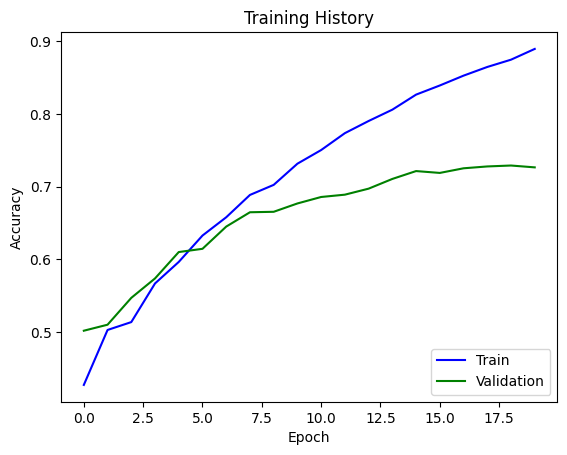

In [ ]:
plt.plot(my_summary.history['accuracy'], c="b")
plt.plot(my_summary.history['val_accuracy'], c="g")
plt.title('Training History')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

#### 1.7. Testing:

In [ ]:
ACC = my_model.evaluate(X_test, y_test, verbose=0)[1]
print("Test Accuracy:", round(ACC, 3))

Test Accuracy: 0.707


## Coding Exercise #0516

#### 1. Document classification with LSTM network (Binary):

In [ ]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets.imdb import load_data, get_word_index       # Movie review data.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
warnings.filterwarnings('ignore')                              # Turn the warnings off.
%matplotlib inline

#### 1.1. Read in the data:

In [ ]:
n_words = 3000    # Size of the vocabulary.
(X_train, y_train), (X_test, y_test) = load_data(num_words=n_words)
n_train_size = X_train.shape[0]

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Check for the shapes.
print("-" * 35)
print("Training data X shape:", X_train.shape)
print("Training data y shape:", y_train.shape)
print("-" * 35)
print("Test data X shape:", X_test.shape)
print("Test data y shape:", y_test.shape)
print("-" * 35)

-----------------------------------
Training data X shape: (25000,)
Training data y shape: (25000,)
-----------------------------------
Test data X shape: (25000,)
Test data y shape: (25000,)
-----------------------------------


#### 1.2. Explore the data:

In [ ]:
# Number of unique values of y = Number of categories of the newswires.
n_cat = pd.Series(y_train).nunique()
n_cat

2

In [ ]:
# Print out an observation (document) contained in X.
# It is encoded as integers (indices).
print(X_train[0])

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 2, 66, 2, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 2, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 2, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 2, 16, 480, 66, 2, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 2, 15, 256, 4, 2, 7, 2, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 2, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 2, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 2, 113, 103, 32, 15, 16, 2, 19, 178, 32]


In [ ]:
# Let's check for length of the first 100 documents.
# We notice that the length is not uniform.
print([len(a) for a in X_train[0:100]])

[218, 189, 141, 550, 147, 43, 123, 562, 233, 130, 450, 99, 117, 238, 109, 129, 163, 752, 212, 177, 129, 140, 256, 888, 93, 142, 220, 193, 171, 221, 174, 647, 233, 162, 597, 234, 51, 336, 139, 231, 704, 142, 861, 132, 122, 570, 55, 214, 103, 186, 113, 169, 469, 138, 302, 766, 351, 146, 59, 206, 107, 152, 186, 431, 147, 684, 383, 324, 252, 263, 787, 211, 314, 118, 390, 132, 710, 306, 167, 115, 95, 158, 156, 82, 502, 314, 190, 174, 60, 145, 214, 659, 408, 515, 461, 202, 238, 170, 107, 171]


In [ ]:
# Download the dictionary to translate the indices.
my_dict = get_word_index(path='imdb_word_index.json')

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# To view the dictionary.
# my_dict

In [ ]:
# Exchange the 'key' and 'value'.
my_dict_inv = {v:k for k,v in my_dict.items()}

In [ ]:
# Translate each document.
i_review = 10                                        # Document number that can be changed at will.
review = list(pd.Series(X_train[i_review]).apply(lambda x: my_dict_inv[x]))
print(' '.join(review))

the clear fact entertaining there life back br is and show of performance stars br actors film him many should movie reasons to and reading and are in of scenes and and of and out compared not boss yes to and show its disappointed fact raw to it justice by br of where clear fact many your way and with city nice are is along wrong not as it way she but this anything up haven't been by who of choices br of you to as this i'd it and who of shot you'll to love for and of you it is sequels of little quest are seen watched front chemistry to simply alive of chris being it is say easy and cry in chemistry but and all it maybe this is wing film job live of and relief and level names and and to be and serial and watch is men go this of wing american from and moving is and put this of jerry for places so work and watch and lot br that from sometimes and make department introduced to and from action at turns in low that in gay i'm of chemistry and i i simply alive it is time done inspector to wat

#### 1.3. Data preprocessing:

In [ ]:
# Padding: newswire lengths are uniformly matched to maxlen.
# Cut away if longer than maxlen and fill with 0s if shorter than maxlen.
X_train = sequence.pad_sequences(X_train, maxlen = 100)
X_test = sequence.pad_sequences(X_test, maxlen = 100)

In [ ]:
# y is already binary. Thus, there is no need to convert to the one-hot-encoding scheme.

#### 1.4. Define the model:

In [ ]:
n_neurons = 50                    # Neurons within each memory cell.
n_input = 100                     # Dimension of the embedding space.

In [ ]:
# LSTM network model.
my_model = Sequential()
my_model.add(Embedding(n_words, n_input))           # n_words = vocabulary size, n_input = dimension of the embedding space.
my_model.add(LSTM(units=n_neurons, return_sequences=False, input_shape=(None, n_input), activation='tanh'))
my_model.add(Dense(1, activation='sigmoid'))    # Binary output!!!

In [ ]:
# View the summary.
my_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

#### 1.5. Define the optimizer and compile:

In [ ]:
n_epochs = 5                      # Number of epochs.
batch_size = 50                    # Size of each batch.
learn_rate = 0.002                 # learning rate.

In [ ]:
# Optimizer and compilation.
my_optimizer=Adam(learning_rate=learn_rate)
my_model.compile(loss="binary_crossentropy", optimizer=my_optimizer, metrics=["accuracy"])

#### 1.6. Train the model and visualize the history:

In [ ]:
my_summary = my_model.fit(X_train, y_train, epochs=n_epochs, batch_size = batch_size, validation_split=0.2, verbose = 1)

Epoch 1/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.7779 - loss: 0.4634 - val_accuracy: 0.8232 - val_loss: 0.3845
Epoch 2/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8633 - loss: 0.3196 - val_accuracy: 0.8390 - val_loss: 0.3641
Epoch 3/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8902 - loss: 0.2687 - val_accuracy: 0.8440 - val_loss: 0.3563
Epoch 4/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9139 - loss: 0.2174 - val_accuracy: 0.8458 - val_loss: 0.3824
Epoch 5/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.9280 - loss: 0.1812 - val_accuracy: 0.8390 - val_loss: 0.4215


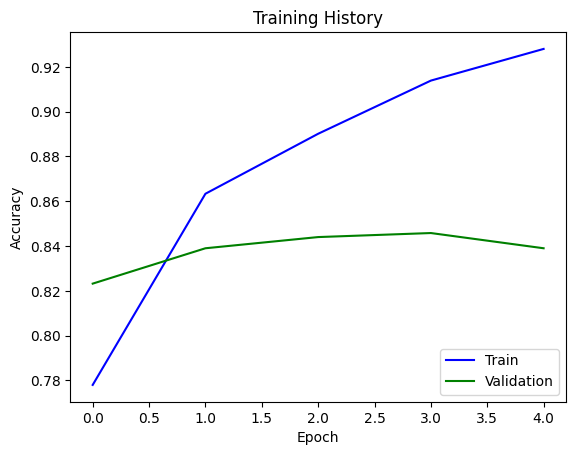

In [ ]:
plt.plot(my_summary.history['accuracy'], c="b")
plt.plot(my_summary.history['val_accuracy'], c="g")
plt.title('Training History')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

#### 1.7. Testing:

In [ ]:
ACC = my_model.evaluate(X_test, y_test, verbose=0)[1]
print("Test Accuracy", round(ACC, 3))

Test Accuracy 0.844


## Coding Exercise #0517

#### 1. Document classification with LSTM + CNN network (Binary):

In [ ]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.datasets.imdb import load_data, get_word_index       # Movie review data.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Conv1D, MaxPooling1D, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
warnings.filterwarnings('ignore')                              # Turn the warnings off.
%matplotlib inline

#### 1.1. Read in the data:

In [ ]:
n_words = 3000                                        # Size of the vocabulary.
(X_train, y_train), (X_test, y_test) = load_data(num_words=n_words)
n_train_size = X_train.shape[0]

In [ ]:
# Check for the shapes.
print("-" * 35)
print("Training data X shape:", X_train.shape)
print("Training data y shape:", y_train.shape)
print("-" * 35)
print("Test data X shape:", X_test.shape)
print("Test data y shape:", y_test.shape)
print("-" * 35)

-----------------------------------
Training data X shape: (25000,)
Training data y shape: (25000,)
-----------------------------------
Test data X shape: (25000,)
Test data y shape: (25000,)
-----------------------------------


#### 1.2. Explore the data:

In [ ]:
# Number of unique values of y = Number of categories of the newswires.
n_cat = pd.Series(y_train).nunique()
n_cat

2

In [ ]:
# Print out an observation (document) contained in X.
# It is encoded as integers (indices).
print(X_train[0])

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 2, 66, 2, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 2, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 2, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 2, 16, 480, 66, 2, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 2, 15, 256, 4, 2, 7, 2, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 2, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 2, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 2, 113, 103, 32, 15, 16, 2, 19, 178, 32]


In [ ]:
# Let's check for length of the first 100 documents.
# We notice that the length is not uniform.
print([len(a) for a in X_train[0:100]])

[218, 189, 141, 550, 147, 43, 123, 562, 233, 130, 450, 99, 117, 238, 109, 129, 163, 752, 212, 177, 129, 140, 256, 888, 93, 142, 220, 193, 171, 221, 174, 647, 233, 162, 597, 234, 51, 336, 139, 231, 704, 142, 861, 132, 122, 570, 55, 214, 103, 186, 113, 169, 469, 138, 302, 766, 351, 146, 59, 206, 107, 152, 186, 431, 147, 684, 383, 324, 252, 263, 787, 211, 314, 118, 390, 132, 710, 306, 167, 115, 95, 158, 156, 82, 502, 314, 190, 174, 60, 145, 214, 659, 408, 515, 461, 202, 238, 170, 107, 171]


In [ ]:
# Download the dictionary to translate the indices.
my_dict = get_word_index(path='imdb_word_index.json')

In [ ]:
# To view the dictionary.
# my_dict

In [ ]:
# Exchange the 'key' and 'value'.
my_dict_inv = {v:k for k, v in my_dict.items()}

In [ ]:
# Translate each document.
i_review = 10                                        # Document number that can be changed at will.
review = list(pd.Series(X_train[i_review]).apply(lambda x: my_dict_inv[x]))
print(' '.join(review))

the clear fact entertaining there life back br is and show of performance stars br actors film him many should movie reasons to and reading and are in of scenes and and of and out compared not boss yes to and show its disappointed fact raw to it justice by br of where clear fact many your way and with city nice are is along wrong not as it way she but this anything up haven't been by who of choices br of you to as this i'd it and who of shot you'll to love for and of you it is sequels of little quest are seen watched front chemistry to simply alive of chris being it is say easy and cry in chemistry but and all it maybe this is wing film job live of and relief and level names and and to be and serial and watch is men go this of wing american from and moving is and put this of jerry for places so work and watch and lot br that from sometimes and make department introduced to and from action at turns in low that in gay i'm of chemistry and i i simply alive it is time done inspector to wat

#### 1.3. Data preprocessing:

In [ ]:
# Padding: newswire lengths are uniformly matched to maxlen.
# Cut away if longer than maxlen and fill with 0s if shorter than maxlen.
X_train = sequence.pad_sequences(X_train, maxlen=100)
X_test = sequence.pad_sequences(X_test, maxlen=100)

In [ ]:
# y is already binary. Thus, there is no need to convert to the one-hot-encoding scheme.

#### 1.4. Define the model:

In [ ]:
drop_prob = 0.5                   # Dropout probability.
n_filters = 64                    # Number of filters (kernels).
k_size = 4                        # Kernel (filter) size.
stride_size = 1                   # Stride.
n_neurons = 50                    # Neurons within each memory cell.
n_input = 100                     # Dimension of the embedding space.

In [ ]:
# LSTM + CNN model..
my_model = Sequential()
my_model.add(Embedding(n_words, n_input))           # n_words = vocabulary size, n_input = dimension of the embedding space.
my_model.add(Dropout(rate=drop_prob))
my_model.add(Conv1D(filters=n_filters, kernel_size=k_size, strides=stride_size, padding='valid', activation='relu'))
my_model.add(MaxPooling1D(pool_size=2))
my_model.add(LSTM(units=n_neurons, return_sequences=False, input_shape=(None, n_input), activation='tanh'))
my_model.add(Dense(1, activation='sigmoid'))

In [ ]:
# View the summary.
my_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

#### 1.5. Define the optimizer and compile:

In [ ]:
n_epochs = 5                      # Number of epochs.
batch_size = 50                    # Size of each batch.
learn_rate = 0.002                 # learning rate.

In [ ]:
# Optimizer and compilation.
my_optimizer=Adam(learning_rate=learn_rate)
my_model.compile(loss="binary_crossentropy", optimizer=my_optimizer, metrics=["accuracy"])

#### 1.6. Train the model and visualize the history:

In [ ]:
my_summary = my_model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size, validation_split=0.2, verbose=1)

Epoch 1/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.7735 - loss: 0.4548 - val_accuracy: 0.8420 - val_loss: 0.3564
Epoch 2/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.8623 - loss: 0.3230 - val_accuracy: 0.8454 - val_loss: 0.3530
Epoch 3/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8839 - loss: 0.2814 - val_accuracy: 0.8544 - val_loss: 0.3436
Epoch 4/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.8993 - loss: 0.2460 - val_accuracy: 0.8484 - val_loss: 0.3540
Epoch 5/5
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9140 - loss: 0.2153 - val_accuracy: 0.8434 - val_loss: 0.3725


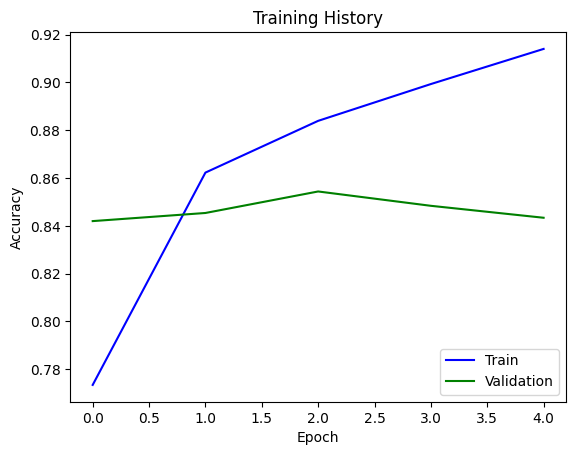

In [ ]:
plt.plot(my_summary.history['accuracy'], c="b")
plt.plot(my_summary.history['val_accuracy'], c="g")
plt.title('Training History')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

#### 1.7. Testing:

In [ ]:
ACC = my_model.evaluate(X_test, y_test, verbose=0)[1]
print("Test Accuracy", round(ACC, 3))

Test Accuracy 0.841
